# Financial Fraud Intelligence
## Système intelligent de détection de fraude bancaire

**Projet de Data Mining — ECE Paris, Bachelor 3 Intelligence Artificielle**

---

### Présentation du projet

Ce notebook construit un système de détection de fraude sur carte bancaire avec le Machine Learning.
L'objectif est d'**identifier le maximum de transactions frauduleuses** (priorité au *recall*),
tout en restant compatible avec la capacité de vérification d'une équipe d'analystes.

**Démarche en bref :**
1. Cadrer le problème : objectif, coûts des erreurs, capacité de vérification, métrique de succès
2. Comprendre les données : qualité, origine des étiquettes, analyse exploratoire (montant, heure, évolution dans le temps)
3. Préparer : **découpage temporel** (le passé pour prédire le futur), création de variables, mise à l'échelle dans un Pipeline
4. Modéliser : une **règle simple** et un **modèle non supervisé** comme points de comparaison, **15 algorithmes supervisés** comparés en validation croisée, comparaison des stratégies contre le déséquilibre (pondération, sous-échantillonnage, SMOTE), optimisation des hyperparamètres
5. Évaluer : seuil fixé par le **coût** et la **capacité**, intervalles de confiance, stabilité dans le temps, explication **SHAP**, analyse des erreurs
6. Exporter le modèle dans `models/`, prêt à être réutilisé

**Équipe :** 3 étudiants — **Cours :** Data Mining — **Établissement :** ECE Paris

---

# Méthodologie CRISP-DM

Ce projet suit la méthodologie **CRISP-DM** (Cross-Industry Standard Process for Data Mining), le standard de l'industrie pour les projets de Data Mining :

1. **Business Understanding** : cadrage du problème, des coûts et de la métrique de succès
2. **Data Understanding** : exploration, qualité et origine des données
3. **Data Preparation** : découpage, nettoyage, création de variables
4. **Modeling** : construction, comparaison et optimisation des modèles
5. **Evaluation** : évaluation sur des données jamais vues, stabilité, explication, erreurs
6. **Deployment** : export du modèle et mise en production envisagée (suivi, réentraînement)

Chaque phase est documentée avec des explications théoriques, des justifications techniques et des interprétations métier.

---

# Introduction générale

## Contexte de la fraude financière

La fraude bancaire est un enjeu majeur pour les institutions financières. Avec l'essor des paiements électroniques et du commerce en ligne, les transactions par carte ont explosé, et les fraudeurs ont trouvé de nouvelles opportunités. Les pertes se comptent en milliards chaque année, sans compter les coûts indirects : réputation, confiance des clients, traitement des litiges.

## Pourquoi la détection automatique est-elle nécessaire ?

Les méthodes traditionnelles (règles fixes, contrôles manuels) ont des limites :

- **Rigidité** : les règles statiques ne s'adaptent pas aux nouvelles techniques de fraude
- **Lenteur** : les contrôles manuels ne suivent pas le volume de transactions en temps réel
- **Coût élevé** : les investigations manuelles mobilisent beaucoup de personnel
- **Taux d'erreur** : les règles simples génèrent de nombreuses fausses alertes

Le **Machine Learning** apprend automatiquement les schémas de fraude passés, traite des millions de transactions et attribue à chacune un **score de risque**.

## Problématique du projet

> **Comment détecter le plus grand nombre possible de transactions frauduleuses, avec un volume d'alertes que l'équipe de vérification peut absorber ?**

Le défi principal est le **déséquilibre des classes** : les fraudes représentent moins de 0,2 % des transactions. Un modèle naïf peut afficher 99,8 % d'accuracy sans détecter une seule fraude.

---

# Installation des dépendances et configuration

Bibliothèques utilisées :

- **Pandas / NumPy** : manipulation de données et calcul numérique
- **Scikit-learn** : algorithmes, validation croisée, métriques, Pipeline
- **LightGBM / XGBoost** : algorithmes de *gradient boosting*, souvent les plus performants sur des données tabulaires
- **imbalanced-learn** : sous-échantillonnage et SMOTE pour traiter le déséquilibre
- **SHAP** : explication des prédictions du modèle
- **Matplotlib / Seaborn** : visualisation
- **Joblib** : sauvegarde du modèle

### Configuration pour Google Colab

Sur Google Colab, décommentez et exécutez la cellule suivante :

In [1]:
# Installation des dépendances (Google Colab ou nouvelle machine)
# !pip install pandas numpy scikit-learn lightgbm xgboost imbalanced-learn shap matplotlib seaborn joblib

### Import des bibliothèques et paramètres globaux

Tous les paramètres du projet sont regroupés ici, pour qu'on puisse les modifier facilement :

- `RANDOM_STATE` : graine aléatoire, pour que les résultats soient **reproductibles**
- `MIN_PRECISION` : précision minimale pour comparer les modèles entre eux (**50 %**)
- `COUT_VERIFICATION` : coût estimé d'une alerte (temps d'un analyste, appel ou SMS au client) — **hypothèse : 5 €**
- `CAPACITE_ALERTES_JOUR` : nombre maximal d'alertes que l'équipe peut vérifier par jour — **hypothèse : 500**

In [2]:
import os
import sys
from pathlib import Path

# ---- Chemins (fonctionne depuis le dossier notebooks/ ou depuis la racine du projet) ----
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ["PYTHONWARNINGS"] = "ignore"

import time
import json
import warnings
from datetime import datetime
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
import shap

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_predict, RandomizedSearchCV, ParameterGrid
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, FunctionTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, precision_recall_curve, roc_curve,
    confusion_matrix, classification_report, make_scorer
)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

# Les 15 algorithmes supervisés comparés
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, ExtraTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier,
    GradientBoostingClassifier, HistGradientBoostingClassifier, IsolationForest
)
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier


warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10

# ---- Paramètres du projet ----
RANDOM_STATE = 42
MIN_PRECISION = 0.50           # comparaison des modèles : au moins 1 alerte sur 2 doit être une vraie fraude
PRECISION_BLOCAGE = 0.90       # au-delà de ce niveau de certitude, la transaction est bloquée directement
COUT_VERIFICATION = 5.0        # € par alerte vérifiée (hypothèse)
CAPACITE_ALERTES_JOUR = 500    # alertes vérifiables par jour (hypothèse)
TEST_SIZE = 0.20
N_JOBS = min(5, os.cpu_count() or 1)

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "creditcard.csv"
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# ---- Création de variables (expliquée en section 3.3) ----
COLONNES_BRUTES = ["Time"] + [f"V{i}" for i in range(1, 29)] + ["Amount"]          # entrée : transaction brute
COLONNES_MODELE = [f"V{i}" for i in range(1, 29)] + ["Amount_log", "Heure_sin", "Heure_cos"]   # entrée du modèle


def heure_du_jour(time_secondes):
    # Heure de la journée (0-24) à partir de Time, en supposant que la collecte commence à minuit
    return (np.asarray(time_secondes, dtype=float) % 86400) / 3600


def ajouter_variables(X):
    # Transforme des transactions brutes (Time, V1..V28, Amount) en variables pour le modèle
    heure = heure_du_jour(X["Time"])
    sortie = X[[f"V{i}" for i in range(1, 29)]].astype(float).copy()
    sortie["Amount_log"] = np.log1p(X["Amount"].astype(float).clip(lower=0))
    sortie["Heure_sin"] = np.sin(2 * np.pi * heure / 24)
    sortie["Heure_cos"] = np.cos(2 * np.pi * heure / 24)
    return sortie[COLONNES_MODELE]



print(f"✓ Bibliothèques importées (scikit-learn {sklearn.__version__}, pandas {pd.__version__}, shap {shap.__version__})")
print(f"✓ Racine du projet : {PROJECT_ROOT}")

✓ Bibliothèques importées (scikit-learn 1.9.1, pandas 3.0.1, shap 0.51.0)
✓ Racine du projet : C:\Users\DIGITAL MARKET\Desktop\Financial_Fraud_Intelligence


---

# PHASE 1 — BUSINESS UNDERSTANDING (Cadrage)

## 1.1 Qu'est-ce qu'une fraude ici ?

Dans ce projet, une **fraude** est une transaction par carte bancaire **réalisée sans le consentement du titulaire** et **reconnue comme telle par la banque** (vol de carte, données de carte volées par *skimming* ou *phishing*, achat en ligne frauduleux…).

## 1.2 Quand détecter : avant ou après le paiement ?

| Option | Principe | Contrainte |
|---|---|---|
| **Temps réel** (avant validation du paiement) | le score est calculé pendant l'autorisation ; on peut bloquer la fraude **avant** que l'argent parte | réponse en quelques millisecondes, seulement l'information disponible à cet instant |
| Analyse a posteriori | on analyse les transactions déjà passées | l'argent est déjà parti, on ne peut que tenter de le récupérer |

**Nous visons la détection en temps réel.** Conséquences :
- le modèle doit répondre **en moins de 10 ms** ;
- chaque variable ne doit utiliser **que l'information disponible au moment de la transaction** ;
- la décision se fait sur **3 niveaux** : *accepter*, *vérifier* (un analyste contacte le client) ou *bloquer* (score très élevé).

## 1.3 Contraintes métier : combien coûtent les erreurs ?

| Erreur | Signification | Coût retenu (hypothèse) |
|---|---|---|
| **Faux négatif (FN)** | une fraude passe | **le montant de la transaction** (perte directe) |
| **Alerte** (vraie ou fausse) | un analyste vérifie la transaction | **5 €** (temps d'analyste, appel ou SMS) |
| **Capacité de vérification** | l'équipe ne peut pas tout vérifier | **500 alertes par jour maximum** |

Ces chiffres sont des **hypothèses de travail** : en entreprise, ils seraient fournis par le métier. Ils sont regroupés en paramètres en haut du notebook et nous testons leur influence (section 4.7).

**Conséquence : le recall est prioritaire.** Une fraude ratée coûte en moyenne plus de 100 €, une vérification 5 €. Comme les fraudes sont **très rares**, chacune compte.

## 1.4 Métrique de succès

L'**accuracy est exclue** : avec 0,17 % de fraudes, répondre toujours « normal » donne 99,83 % d'accuracy sans détecter une seule fraude.

Nous utilisons trois niveaux de mesure :

1. **Pour comparer les modèles : le Recall à Precision ≥ 50 %.** Pour chaque modèle, c'est le plus grand taux de détection atteignable avec au moins une alerte sur deux qui soit une vraie fraude. On compare ainsi tous les modèles **à qualité d'alerte égale**. La **PR-AUC** (aire sous la courbe precision-recall) départage les ex æquo.
2. **Pour choisir le seuil de décision : le coût total**, sous la contrainte de **capacité** (500 alertes par jour maximum).
3. **Pour juger le résultat final :** les critères de réussite ci-dessous.

| Critère de réussite | Objectif |
|---|---|
| Recall (détection des fraudes) | > 80 % |
| Volume d'alertes | ≤ 500 par jour |
| PR-AUC | > 0,75 |
| Temps de prédiction | < 10 ms par transaction |

## KPI métier

**Recall** : part des fraudes détectées
$$ \text{Recall} = \frac{TP}{TP + FN} $$

**Precision** : part des alertes qui sont de vraies fraudes
$$ \text{Precision} = \frac{TP}{TP + FP} $$

**Taux de fausse alerte (FPR)** : part des clients honnêtes dérangés à tort
$$ \text{FPR} = \frac{FP}{FP + TN} $$

**F1 / F2** : compromis entre precision et recall (le F2 donne deux fois plus de poids au recall)
$$ F_\beta = (1+\beta^2) \times \frac{\text{Precision} \times \text{Recall}}{\beta^2 \times \text{Precision} + \text{Recall}} $$

**Coût total** : $\text{Coût} = \text{Nb d'alertes} \times 5\,€ + \sum \text{montants des fraudes ratées}$

---

# PHASE 2 — DATA UNDERSTANDING (Compréhension des données)

## 2.1 Source et collecte des données

Nous utilisons le dataset **Credit Card Fraud Detection** de Kaggle, une référence académique pour la détection de fraude.

- **Source** : https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
- **Collecteur** : Machine Learning Group — Université Libre de Bruxelles (ULB), avec Worldline
- **Période** : deux jours de transactions, septembre 2013, porteurs de cartes européens
- **Taille** : 284 807 transactions, dont 492 fraudes (0,172 %), 31 variables

### Variables disponibles

1. **Time** : secondes écoulées depuis la première transaction du dataset
2. **V1 à V28** : variables issues d'une **ACP (PCA)**, anonymisées pour des raisons de confidentialité
3. **Amount** : montant de la transaction
4. **Class** : variable cible (0 = normale, 1 = frauduleuse)

### Ce qui manque par rapport à un vrai système

Un système bancaire réel rassemblerait plusieurs sources : transactions, **clients**, **cartes**, **appareils**, **commerçants**, **pays**… Ici, tout a été **fusionné et anonymisé** dans une seule table, **sans identifiant de client ni de carte**. Conséquences :
- impossible de calculer des variables de **comportement** (nombre de transactions récentes sur la carte, écart aux habitudes du client, nouvel appareil ou nouveau pays) ;
- impossible de garantir qu'un même client n'apparaît pas à la fois dans le train et dans le test.

Ce sont des **limites du dataset**, que nous rappelons en conclusion.

## 2.2 Chargement des données

Nous chargeons le fichier CSV dans un **DataFrame Pandas**, la structure tabulaire de référence en Python.

**Note** : le fichier `creditcard.csv` doit être placé dans `data/raw/`. Sur Google Colab, uploadez-le puis modifiez `DATA_PATH`.

In [3]:
# Pour Google Colab : DATA_PATH = Path("creditcard.csv")
df = pd.read_csv(DATA_PATH)

print("✓ Dataset chargé avec succès")
print(f"  - Dimensions : {df.shape[0]:,} lignes × {df.shape[1]} colonnes")
print(f"  - Taille en mémoire : {df.memory_usage(deep=True).sum() / 1024**2:.1f} Mo")
display(df.head())

✓ Dataset chargé avec succès
  - Dimensions : 284,807 lignes × 31 colonnes
  - Taille en mémoire : 67.4 Mo


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2.3 Qualité des données

Nous vérifions :
- les **valeurs manquantes**, qui peuvent faire échouer les modèles ;
- les **doublons**, qui biaisent l'évaluation si une même transaction se retrouve dans le train et dans le test ;
- les **types** et les **formats** ;
- la **cohérence du temps** : `Time` doit être positif, croissant, et couvrir environ 48 heures ;
- la **cohérence des montants** : pas de montant négatif.

In [4]:
print("=== Types de données ===")
print(df.dtypes.value_counts().to_string())

missing = df.isnull().sum()
print("\n=== Valeurs manquantes ===")
print(missing[missing > 0] if missing.sum() > 0 else "Aucune valeur manquante")

n_dup = df.duplicated().sum()
print("\n=== Doublons ===")
print(f"{n_dup:,} lignes en double ({n_dup / len(df) * 100:.2f} %), dont {df[df.duplicated()]['Class'].sum()} fraudes")

print("\n=== Cohérence du temps et des montants ===")
print(f"Time : de {df['Time'].min():.0f} s à {df['Time'].max():.0f} s, soit {df['Time'].max() / 3600:.1f} heures")
print(f"Time toujours croissant : {df['Time'].is_monotonic_increasing}")
print(f"Montants négatifs : {(df['Amount'] < 0).sum()} — montants nuls : {(df['Amount'] == 0).sum():,}")
print(f"Valeurs de Class : {sorted(df['Class'].unique())}")

JOURS = df["Time"].max() / 86400
TX_PAR_JOUR = len(df) / JOURS
print(f"\nVolume moyen : {TX_PAR_JOUR:,.0f} transactions par jour")

=== Types de données ===
float64    30
int64       1

=== Valeurs manquantes ===
Aucune valeur manquante

=== Doublons ===
1,081 lignes en double (0.38 %), dont 19 fraudes

=== Cohérence du temps et des montants ===
Time : de 0 s à 172792 s, soit 48.0 heures
Time toujours croissant : True
Montants négatifs : 0 — montants nuls : 1,825
Valeurs de Class : [np.int64(0), np.int64(1)]

Volume moyen : 142,410 transactions par jour


**Lecture** : le dataset est propre. Il n'y a ni valeur manquante ni montant négatif, le temps est croissant et couvre bien 48 heures. Les 1 081 doublons seront supprimés. Il y a quelques transactions à 0 € (vérifications de carte), que nous gardons, car elles font partie du flux réel.

## 2.4 D'où viennent les étiquettes « fraude » ?

Toute la qualité du modèle dépend de la qualité de l'étiquette `Class`. Dans une banque, une transaction est étiquetée « fraude » quand :
- le **titulaire la conteste** (*chargeback*) et la contestation est validée ;
- ou un **analyste la confirme** après une alerte.

Cela pose deux problèmes à garder en tête :
1. **Fraudes inconnues** : certaines fraudes ne sont **jamais signalées** (petits montants que le client ne remarque pas) ou pas encore. Elles sont étiquetées « normales » à tort. Le vrai taux de fraude est donc probablement **un peu plus élevé** que 0,17 %, et une partie des « fausses alertes » du modèle sont peut-être de vraies fraudes non détectées.
2. **Délai** : la confirmation d'une fraude arrive souvent **plusieurs semaines** après la transaction. Cela compte pour le suivi en production (phase 6).

## 2.5 Analyse exploratoire (EDA)

### Déséquilibre des classes

Transactions normales (0)     : 284,315 (99.827 %)
Transactions frauduleuses (1) :     492 (0.173 %)
Ratio : 578 transactions normales pour 1 fraude


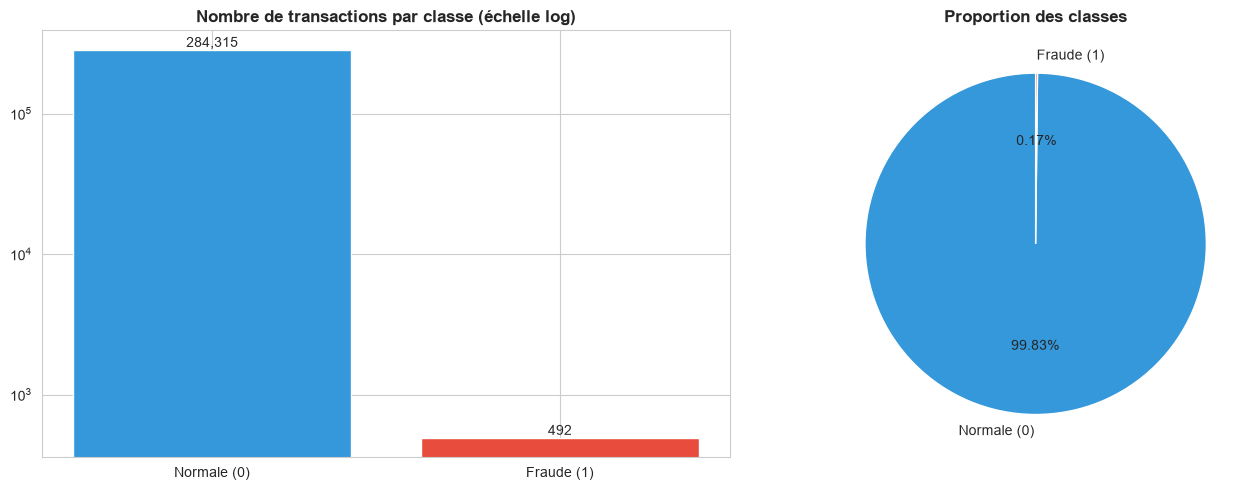

In [5]:
class_counts = df["Class"].value_counts().sort_index()
class_pct = df["Class"].value_counts(normalize=True).sort_index() * 100
print(f"Transactions normales (0)     : {class_counts[0]:>7,} ({class_pct[0]:.3f} %)")
print(f"Transactions frauduleuses (1) : {class_counts[1]:>7,} ({class_pct[1]:.3f} %)")
print(f"Ratio : {class_counts[0] / class_counts[1]:.0f} transactions normales pour 1 fraude")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(["Normale (0)", "Fraude (1)"], class_counts.values, color=["#3498db", "#e74c3c"])
axes[0].set_yscale("log")
axes[0].set_title("Nombre de transactions par classe (échelle log)", fontweight="bold")
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")
axes[1].pie(class_counts, labels=["Normale (0)", "Fraude (1)"], autopct="%1.2f%%",
            colors=["#3498db", "#e74c3c"], startangle=90)
axes[1].set_title("Proportion des classes", fontweight="bold")
plt.tight_layout()
plt.show()

**Lecture** : environ **578 transactions normales pour 1 fraude**. Sur une échelle normale, la barre des fraudes serait invisible. Ce déséquilibre guide tous nos choix : métriques adaptées, validation croisée **stratifiée**, techniques de rééquilibrage, ajustement du seuil.

### Montant des transactions

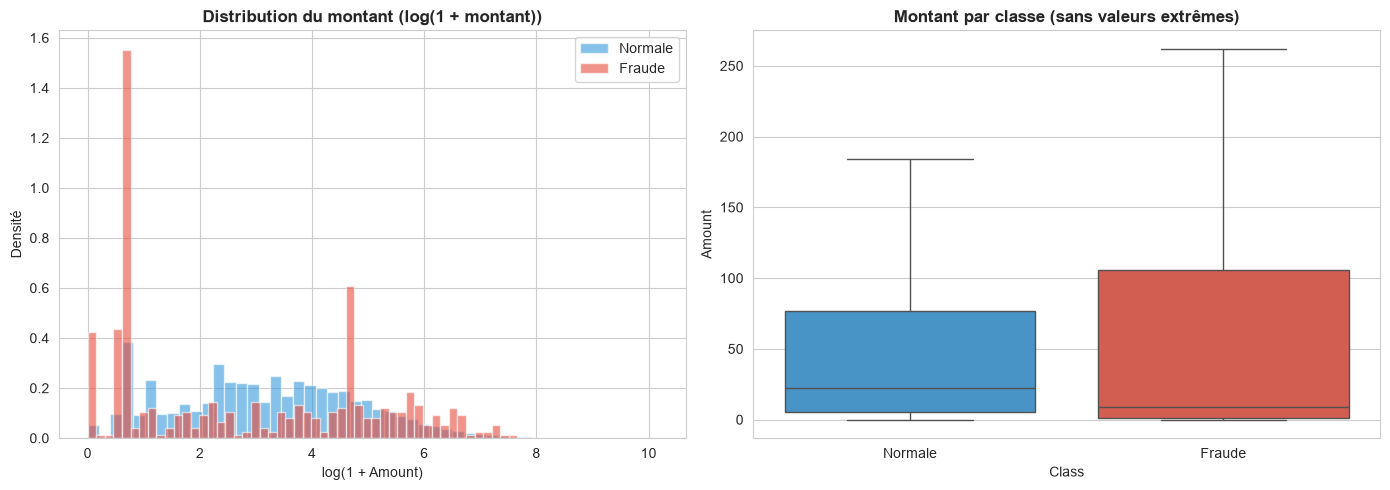

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
Normale,284315.0,88.29,250.11,0.0,5.65,22.00,77.05,25691.16
Fraude,492.0,122.21,256.68,0.0,1.00,9.25,105.89,2125.87


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for cls, color, label in [(0, "#3498db", "Normale"), (1, "#e74c3c", "Fraude")]:
    axes[0].hist(np.log1p(df.loc[df["Class"] == cls, "Amount"]), bins=50, alpha=0.6,
                 density=True, color=color, label=label)
axes[0].set_title("Distribution du montant (log(1 + montant))", fontweight="bold")
axes[0].set_xlabel("log(1 + Amount)")
axes[0].set_ylabel("Densité")
axes[0].legend()

sns.boxplot(data=df, x="Class", y="Amount", hue="Class", ax=axes[1], palette=["#3498db", "#e74c3c"],
            showfliers=False, legend=False)
axes[1].set_xticks([0, 1], ["Normale", "Fraude"])
axes[1].set_title("Montant par classe (sans valeurs extrêmes)", fontweight="bold")
plt.tight_layout()
plt.show()

display(df.groupby("Class")["Amount"].describe().rename(index={0: "Normale", 1: "Fraude"}).round(2))

**Lecture** : les montants sont très **asymétriques** (beaucoup de petits montants, quelques très gros). La médiane des fraudes est **plus faible** que celle des transactions normales : les fraudeurs testent souvent la carte avec de petits montants. Le montant seul ne suffit pas à détecter la fraude. Nous utiliserons son logarithme, qui réduit l'asymétrie.

### Heure de la journée et évolution dans le temps

`Time` compte les secondes depuis le début de la collecte. En supposant qu'elle commence à minuit (hypothèse usuelle pour ce dataset), on en déduit **l'heure de la journée**.

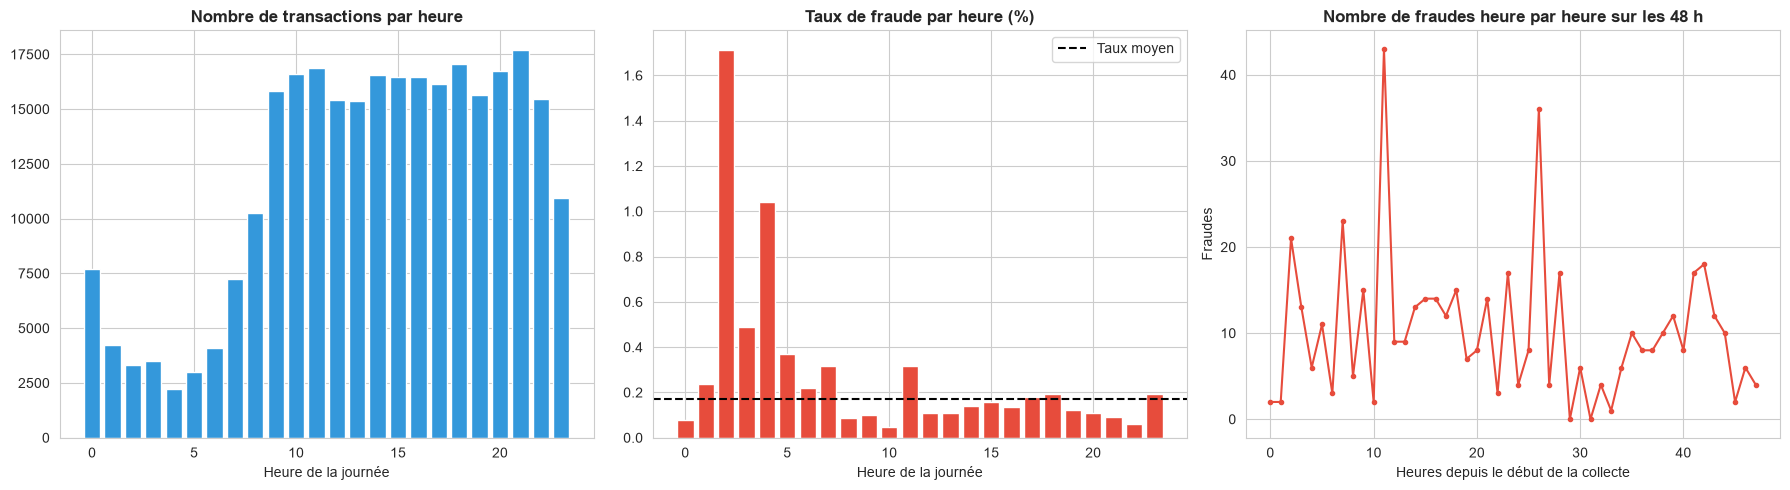

Heures avec le plus fort taux de fraude :


,transactions,fraudes,taux_fraude_%
Heure,,,
2,3328,57,1.713
4,2209,23,1.041
3,3492,17,0.487
5,2990,11,0.368
7,7243,23,0.318


In [7]:
df["Heure"] = heure_du_jour(df["Time"]).astype(int)
par_heure = df.groupby("Heure").agg(transactions=("Class", "size"), fraudes=("Class", "sum"))
par_heure["taux_fraude_%"] = par_heure["fraudes"] / par_heure["transactions"] * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].bar(par_heure.index, par_heure["transactions"], color="#3498db")
axes[0].set_title("Nombre de transactions par heure", fontweight="bold")
axes[0].set_xlabel("Heure de la journée")

axes[1].bar(par_heure.index, par_heure["taux_fraude_%"], color="#e74c3c")
axes[1].axhline(df["Class"].mean() * 100, color="black", ls="--", label="Taux moyen")
axes[1].set_title("Taux de fraude par heure (%)", fontweight="bold")
axes[1].set_xlabel("Heure de la journée")
axes[1].legend()

heure_abs = (df["Time"] // 3600).astype(int)
evolution = df.groupby(heure_abs)["Class"].agg(["size", "sum"])
axes[2].plot(evolution.index, evolution["sum"], color="#e74c3c", marker=".")
axes[2].set_title("Nombre de fraudes heure par heure sur les 48 h", fontweight="bold")
axes[2].set_xlabel("Heures depuis le début de la collecte")
axes[2].set_ylabel("Fraudes")
plt.tight_layout()
plt.show()

df = df.drop(columns="Heure")
print("Heures avec le plus fort taux de fraude :")
display(par_heure.sort_values("taux_fraude_%", ascending=False).head(5).round(3))

**Lecture** :
- L'activité suit un **rythme jour / nuit** très net : peu de transactions entre 1 h et 7 h, ce qui confirme l'hypothèse « la collecte commence à minuit ».
- Le **taux de fraude est bien plus élevé la nuit** : les fraudeurs agissent quand l'activité normale est faible et que les titulaires dorment. L'heure est donc une variable utile, que nous allons créer.
- Les fraudes arrivent **par vagues** au cours des 48 heures, pas de façon régulière. Les performances du modèle pourront donc varier selon la période (nous le vérifierons en section 5.4).

### Variables les plus liées à la fraude

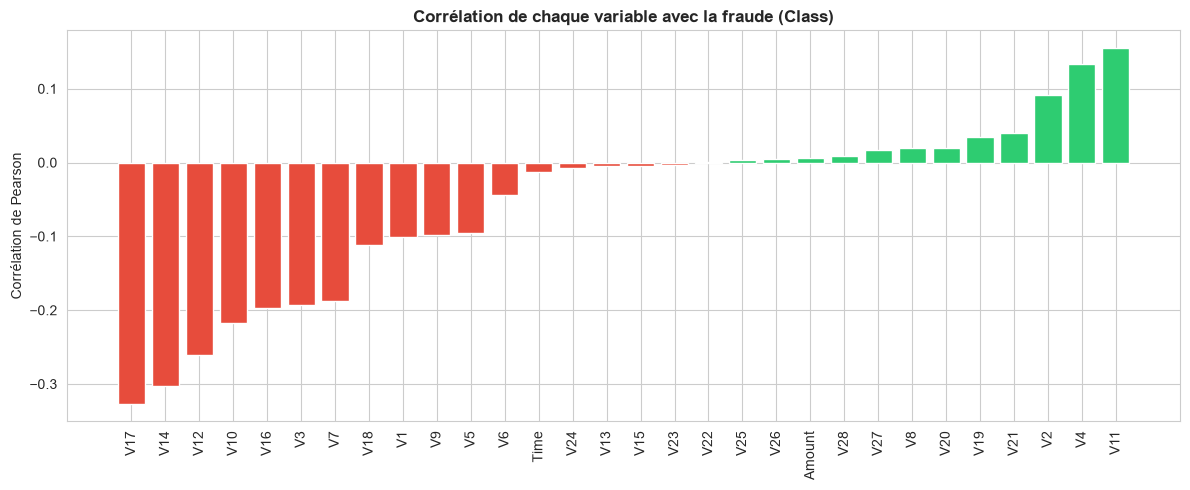

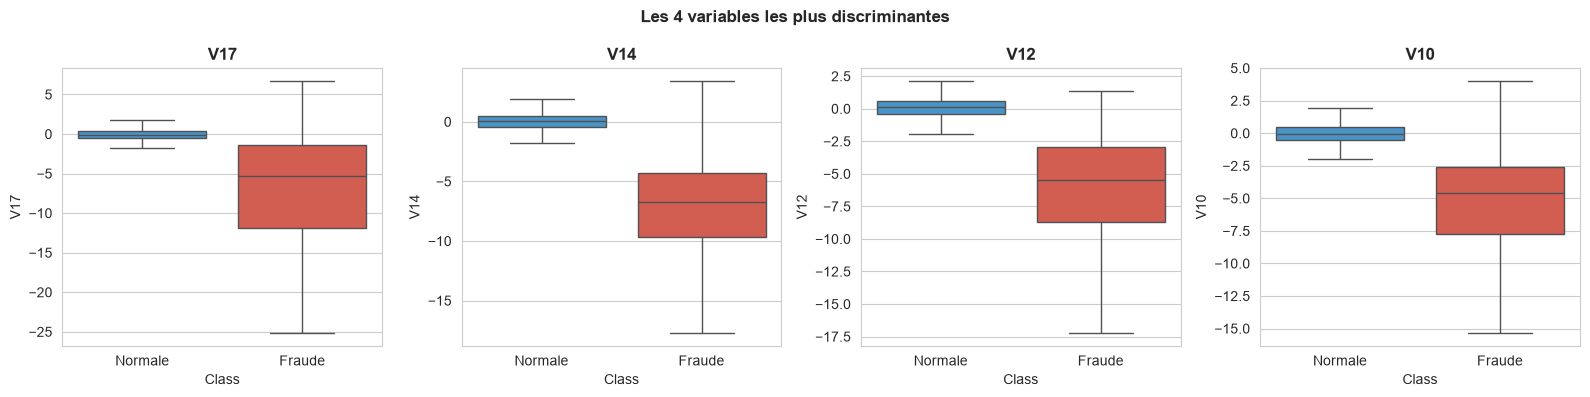

Variables les plus corrélées à la fraude : ['V17', 'V14', 'V12', 'V10']


In [8]:
corr_cible = df.drop(columns="Class").corrwith(df["Class"]).sort_values()

plt.figure(figsize=(12, 5))
plt.bar(corr_cible.index, corr_cible.values, color=["#e74c3c" if v < 0 else "#2ecc71" for v in corr_cible.values])
plt.xticks(rotation=90)
plt.title("Corrélation de chaque variable avec la fraude (Class)", fontweight="bold")
plt.ylabel("Corrélation de Pearson")
plt.tight_layout()
plt.show()

top4 = corr_cible.abs().sort_values(ascending=False).head(4).index.tolist()
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, var in zip(axes, top4):
    sns.boxplot(data=df, x="Class", y=var, hue="Class", ax=ax, palette=["#3498db", "#e74c3c"],
                showfliers=False, legend=False)
    ax.set_xticks([0, 1], ["Normale", "Fraude"])
    ax.set_title(var, fontweight="bold")
plt.suptitle("Les 4 variables les plus discriminantes", fontweight="bold")
plt.tight_layout()
plt.show()
print("Variables les plus corrélées à la fraude :", top4)

**Lecture** : quelques variables (V17, V14, V12, V10) ont des distributions **très différentes** entre fraudes et transactions normales : les fraudes prennent des valeurs nettement plus basses. Ce sont des signaux forts. Nous utiliserons la meilleure d'entre elles pour construire une **règle simple**, qui servira de point de comparaison.

### Synthèse

- Données propres : aucune valeur manquante, **1 081 doublons** à supprimer
- **Déséquilibre extrême** : 0,17 % de fraudes
- Fraude plus fréquente **la nuit** et arrivant **par vagues**
- Plusieurs variables PCA très discriminantes ; montant peu discriminant à lui seul
- Échelles très différentes entre variables : une **mise à l'échelle** sera nécessaire pour certains modèles

---

# PHASE 3 — DATA PREPARATION (Préparation des données)

## 3.1 Suppression des doublons

In [9]:
n_avant = len(df)
df = df.drop_duplicates().sort_values("Time", kind="stable").reset_index(drop=True)
print(f"Avant : {n_avant:,} lignes — Après : {len(df):,} lignes — Supprimés : {n_avant - len(df):,}")
print(f"Fraudes restantes : {df['Class'].sum()}")

Avant : 284,807 lignes — Après : 283,726 lignes — Supprimés : 1,081
Fraudes restantes : 473


## 3.2 Découpage Train / Test : temporel, avant toute transformation

### Pourquoi découper avant de transformer ?

Toute transformation qui « apprend » quelque chose sur les données (une moyenne, une médiane, une échelle…) doit être apprise **uniquement sur le train**. Sinon, des informations du test fuient dans le modèle (*data leakage*) et les scores sont trop optimistes. Nous découpons donc **en premier**.

### Pourquoi un découpage temporel ?

En production, le modèle est entraîné sur le **passé** et utilisé sur le **futur**. Un découpage aléatoire mélange les deux périodes : le modèle « voit » des transactions postérieures à celles qu'il doit prédire, et peut profiter des **vagues de fraude** observées en phase 2. Nous utilisons donc :
- **Train** = les 80 % de transactions **les plus anciennes**
- **Test** = les 20 % **les plus récentes** (environ les 9 dernières heures), mises de côté jusqu'à la toute fin

Un découpage temporel ne peut pas être stratifié. Nous vérifions donc que la proportion de fraudes reste comparable. À l'intérieur du train, la validation croisée sera **stratifiée**, pour garder assez de fraudes dans chaque pli. En section 5.4, nous comparerons avec un découpage aléatoire stratifié pour mesurer l'impact de ce choix.

**Note** : sans identifiant client, nous ne pouvons pas vérifier qu'un même client n'apparaît pas des deux côtés.

In [10]:
X = df[COLONNES_BRUTES]
y = df["Class"]

coupure = int(len(df) * (1 - TEST_SIZE))
X_train, X_test = X.iloc[:coupure], X.iloc[coupure:]
y_train, y_test = y.iloc[:coupure], y.iloc[coupure:]

print(f"Train : {len(X_train):,} transactions, de 0 h à {X_train['Time'].max() / 3600:.1f} h — "
      f"{y_train.sum()} fraudes ({y_train.mean() * 100:.3f} %)")
print(f"Test  : {len(X_test):,} transactions, de {X_test['Time'].min() / 3600:.1f} h à {X_test['Time'].max() / 3600:.1f} h — "
      f"{y_test.sum()} fraudes ({y_test.mean() * 100:.3f} %)")

Train : 226,980 transactions, de 0 h à 40.3 h — 399 fraudes (0.176 %)
Test  : 56,746 transactions, de 40.3 h à 48.0 h — 74 fraudes (0.130 %)


## 3.3 Création de variables

Une bonne variable de fraude décrit **le comportement** : vitesse d'utilisation de la carte, écart aux habitudes du client, nouvel appareil, commerçant à risque… Sans identifiant de carte ni de client, ces variables sont **impossibles** à construire ici. Nous créons celles qui sont possibles, et qui respectent toutes la règle du temps réel : **elles n'utilisent que la transaction elle-même**.

| Variable | Calcul | Pourquoi |
|---|---|---|
| `Amount_log` | log(1 + montant) | réduit l'asymétrie des montants |
| `Heure_sin`, `Heure_cos` | heure de la journée encodée sur un cercle | la fraude est plus fréquente la nuit ; l'encodage cyclique dit au modèle que 23 h et 0 h sont proches |
| ~~`Time`~~ | supprimé | c'est un compteur depuis le début de la collecte : pour une transaction future, sa valeur n'a aucun sens |

Ces transformations sont intégrées au **Pipeline** du modèle : le modèle exporté reçoit une transaction **brute** et la transforme lui-même.

In [ ]:
print("Avant :", list(X_train.columns[:3]), "...", list(X_train.columns[-2:]))
apercu = ajouter_variables(X_train.head())
print("Après :", list(apercu.columns[:3]), "...", list(apercu.columns[-3:]))
display(apercu[["V1", "V2", "Amount_log", "Heure_sin", "Heure_cos"]].round(3))

Avant : ['Time', 'V1', 'V2'] ... ['V28', 'Amount']
Après : ['V1', 'V2', 'V3'] ... ['Amount_log', 'Heure_sin', 'Heure_cos']


,V1,V2,Amount_log,Heure_sin,Heure_cos
0,-1.360,-0.073,5.015,0.0,1.0
1,1.192,0.266,1.306,0.0,1.0
2,-1.358,-1.340,5.939,0.0,1.0
3,-0.966,-0.185,4.824,0.0,1.0
4,-1.158,0.878,4.263,0.0,1.0


## 3.4 Nettoyage et mise à l'échelle dans un Pipeline

- **Valeurs manquantes** : aucune, pas d'imputation nécessaire.
- **Catégories** : aucune variable catégorielle, pas d'encodage nécessaire.
- **Valeurs aberrantes** : nous les **gardons**, car une valeur extrême est souvent justement le signe d'une fraude. Nous utilisons un **RobustScaler** (basé sur la médiane et l'écart interquartile), peu sensible à ces valeurs.

### Pourquoi mettre à l'échelle ?

Les modèles basés sur des **distances** (KNN) ou sur une **optimisation par gradient** (régression logistique, SVM, SGD) sont perturbés quand les variables ont des échelles très différentes. Les modèles à base d'arbres n'y sont pas sensibles, mais la mise à l'échelle ne les gêne pas.

### Pourquoi un Pipeline ?

Le **Pipeline** enchaîne : *création de variables → mise à l'échelle → modèle*.
- En validation croisée, le scaler est **réappris à chaque pli**, uniquement sur la partie entraînement : aucune fuite d'information.
- À l'export, tout est sauvegardé **ensemble** : une transaction brute peut être donnée directement au pipeline, qui renvoie un score.

In [12]:
def creer_pipeline(modele, echantillonneur=None):
    # Création de variables + mise à l'échelle (+ rééchantillonnage éventuel) + modèle
    etapes = [("variables", FunctionTransformer(ajouter_variables)), ("scaler", RobustScaler())]
    if echantillonneur is None:
        return Pipeline(etapes + [("model", modele)])
    # imblearn : le rééchantillonnage n'est appliqué QUE pendant l'entraînement, jamais à la prédiction
    return ImbPipeline(etapes + [("sampler", echantillonneur), ("model", modele)])

print(creer_pipeline(LogisticRegression()))

Pipeline(steps=[('variables',
                 FunctionTransformer(func=<function ajouter_variables at 0x00000215CD8E2C00>)),
                ('scaler', RobustScaler()), ('model', LogisticRegression())])


---

# PHASE 4 — MODELING (Modélisation)

## 4.1 Protocole de comparaison

1. **Validation croisée stratifiée à 5 plis** sur le train : chaque modèle est entraîné 5 fois sur 80 % du train et prédit les 20 % restants. On obtient une prédiction **hors échantillon** pour chaque transaction du train.
2. Sur ces prédictions, nous calculons Precision, Recall, F1, F2, PR-AUC et ROC-AUC.
3. **Critère de sélection : le Recall à Precision ≥ 50 %**, la PR-AUC départageant les ex æquo.

**Pourquoi pas le recall « brut » ?** Au seuil par défaut, le recall dépend surtout de la prudence du modèle : un modèle qui signale beaucoup de transactions a un recall élevé, mais une précision catastrophique. En fixant la même précision minimale pour tous, on compare leur **vraie capacité de détection**.

In [13]:
def scores_fraude(estimateur, X):
    # Score de fraude : probabilité si le modèle en fournit une, sinon score de décision
    if hasattr(estimateur, "predict_proba"):
        return estimateur.predict_proba(X)[:, 1]
    return estimateur.decision_function(X)


def recall_a_precision(y_true, scores, min_precision=MIN_PRECISION):
    # Plus grand recall atteignable avec une précision >= min_precision, et le seuil correspondant
    precision, recall, seuils = precision_recall_curve(y_true, scores)
    precision, recall = precision[:-1], recall[:-1]
    ok = np.where(precision >= min_precision)[0]
    if len(ok) == 0:
        return 0.0, np.nan
    meilleur = recall[ok].max()
    idx = ok[recall[ok] == meilleur].max()      # à recall égal, seuil le plus haut
    return float(meilleur), float(seuils[idx])


def metriques(y_true, y_pred, scores=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    m = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "F2": fbeta_score(y_true, y_pred, beta=2, zero_division=0),
        "FPR": fp / (fp + tn),
        "TP": tp, "FN": fn, "FP": fp, "TN": tn,
    }
    if scores is not None:
        m["ROC-AUC"] = roc_auc_score(y_true, scores)
        m["PR-AUC"] = average_precision_score(y_true, scores)
    return m


def ligne_resultat(nom, type_modele, y_true, scores, seuil_defaut, duree):
    m = metriques(y_true, (scores >= seuil_defaut).astype(int), scores)
    return {
        "Modèle": nom, "Type": type_modele,
        "Recall @ P≥50%": recall_a_precision(y_true, scores)[0],
        "PR-AUC": m["PR-AUC"], "ROC-AUC": m["ROC-AUC"],
        "Recall (seuil défaut)": m["Recall"], "Precision (seuil défaut)": m["Precision"],
        "F1 (seuil défaut)": m["F1"], "F2 (seuil défaut)": m["F2"],
        "Durée (s)": round(duree, 1),
    }


cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
resultats, scores_oof = [], {}

## 4.2 Point de comparaison n°1 : une règle simple

Avant tout Machine Learning, demandons-nous ce que ferait une **règle métier simple** : « alerter si la variable la plus discriminante (V14) est très basse ». Le seuil de la règle est choisi sur le train pour maximiser le recall avec une précision ≥ 50 %.

Si un modèle complexe ne fait pas nettement mieux que cette règle, il ne vaut pas sa complexité.

In [14]:
debut = time.time()
score_regle = -X_train["V14"].to_numpy()             # plus V14 est bas, plus c'est suspect
_, SEUIL_REGLE = recall_a_precision(y_train, score_regle)
resultats.append(ligne_resultat("Règle simple (V14)", "Règle", y_train, score_regle, SEUIL_REGLE, time.time() - debut))
scores_oof["Règle simple (V14)"] = score_regle
print(f"Règle : alerte si V14 < {-SEUIL_REGLE:.2f}")
print(f"Recall à Precision ≥ 50 % : {resultats[-1]['Recall @ P≥50%']:.3f} — PR-AUC : {resultats[-1]['PR-AUC']:.3f}")

Règle : alerte si V14 < -4.33
Recall à Precision ≥ 50 % : 0.754 — PR-AUC : 0.601


## 4.3 Point de comparaison n°2 : un modèle non supervisé (Isolation Forest)

**Isolation Forest** n'utilise **pas les étiquettes** : il repère les transactions *inhabituelles* (anomalies), en partant du principe qu'elles sont plus faciles à isoler. C'est l'approche à utiliser quand on n'a pas (ou peu) de fraudes étiquetées. La comparaison montre ce que **les étiquettes apportent**.

In [15]:
debut = time.time()
score_iso = np.zeros(len(y_train))
for idx_tr, idx_va in cv5.split(X_train, y_train):
    iso = creer_pipeline(IsolationForest(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))
    iso.fit(X_train.iloc[idx_tr])                     # sans les étiquettes
    score_iso[idx_va] = -iso.decision_function(X_train.iloc[idx_va])   # plus c'est anormal, plus le score est haut
seuil_iso = np.quantile(score_iso, 1 - y_train.mean())  # alerte sur la même proportion que le taux de fraude
resultats.append(ligne_resultat("Isolation Forest", "Non supervisé", y_train, score_iso, seuil_iso, time.time() - debut))
scores_oof["Isolation Forest"] = score_iso
print(f"Recall à Precision ≥ 50 % : {resultats[-1]['Recall @ P≥50%']:.3f} — PR-AUC : {resultats[-1]['PR-AUC']:.3f}")

Recall à Precision ≥ 50 % : 0.030 — PR-AUC : 0.187


## 4.4 Les 15 algorithmes supervisés

| Famille | Modèles | Principe |
|---|---|---|
| **Linéaires** | Logistic Regression, Ridge Classifier, SGD Classifier, Linear SVC | Frontière de décision linéaire ; rapides et interprétables. La Logistic Regression est notre **modèle de base**. |
| **Voisinage** | KNN | Une transaction est classée comme ses *k* voisines les plus proches |
| **Arbres simples** | Decision Tree, Extra Tree | Suite de règles « si… alors… » ; lisibles mais instables |
| **Bagging** | Random Forest, Extra Trees | Des centaines d'arbres votent ; robustes |
| **Boosting** | AdaBoost, Gradient Boosting, Hist Gradient Boosting, **LightGBM**, **XGBoost** | Les arbres sont construits les uns après les autres pour corriger les erreurs des précédents. LightGBM et XGBoost sont les références de l'industrie sur les données tabulaires. |
| **Probabiliste** | Gaussian Naive Bayes | Théorème de Bayes, en supposant les variables indépendantes |

### Gestion du déséquilibre (1re approche) : la pondération des classes

Quand c'est possible, nous utilisons `class_weight="balanced"` (ou `scale_pos_weight` pour XGBoost) : chaque fraude « pèse » environ 600 fois plus qu'une transaction normale pendant l'apprentissage. Le modèle est poussé à ne pas ignorer la classe rare, **sans créer de données artificielles**. Les autres techniques (sous-échantillonnage, SMOTE) seront comparées en section 4.5.

⏱️ La cellule suivante entraîne 15 × 5 = 75 modèles : comptez **15 à 25 minutes**.

In [16]:
RATIO = float((y_train == 0).sum() / (y_train == 1).sum())

modeles = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Ridge Classifier": RidgeClassifier(class_weight="balanced"),
    "SGD Classifier": SGDClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "Extra Tree": ExtraTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1),
    "Extra Trees": ExtraTreesClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1),
    "AdaBoost": AdaBoostClassifier(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "LightGBM": LGBMClassifier(class_weight="balanced", subsample_freq=1, random_state=RANDOM_STATE,
                               n_jobs=1, verbose=-1),
    "XGBoost": XGBClassifier(scale_pos_weight=RATIO, tree_method="hist", eval_metric="aucpr",
                             random_state=RANDOM_STATE, n_jobs=1),
    "Gaussian NB": GaussianNB(),
    "Linear SVC": LinearSVC(class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE),
}

for nom, modele in modeles.items():
    debut = time.time()
    pipe = creer_pipeline(modele)
    methode = "predict_proba" if hasattr(pipe, "predict_proba") else "decision_function"
    s = cross_val_predict(pipe, X_train, y_train, cv=cv5, method=methode, n_jobs=N_JOBS)
    s = s[:, 1] if s.ndim == 2 else s
    scores_oof[nom] = s
    resultats.append(ligne_resultat(nom, "Supervisé", y_train, s,
                                    0.5 if methode == "predict_proba" else 0.0, time.time() - debut))
    print(f"✓ {nom:<24} Recall@P≥50% = {resultats[-1]['Recall @ P≥50%']:.3f} | "
          f"PR-AUC = {resultats[-1]['PR-AUC']:.3f} | {time.time() - debut:5.0f} s")

comparaison = (pd.DataFrame(resultats)
               .sort_values(["Recall @ P≥50%", "PR-AUC"], ascending=False)
               .reset_index(drop=True))
comparaison.index = comparaison.index + 1
display(comparaison.style.format(precision=3).background_gradient(
    subset=["Recall @ P≥50%", "PR-AUC"], cmap="Greens"))

✓ Logistic Regression      Recall@P≥50% = 0.840 | PR-AUC = 0.711 |    11 s
✓ Ridge Classifier         Recall@P≥50% = 0.000 | PR-AUC = 0.259 |     3 s
✓ SGD Classifier           Recall@P≥50% = 0.822 | PR-AUC = 0.668 |     7 s
✓ KNN                      Recall@P≥50% = 0.832 | PR-AUC = 0.784 |    88 s
✓ Decision Tree            Recall@P≥50% = 0.737 | PR-AUC = 0.572 |    12 s
✓ Extra Tree               Recall@P≥50% = 0.734 | PR-AUC = 0.538 |     2 s
✓ Random Forest            Recall@P≥50% = 0.867 | PR-AUC = 0.846 |    97 s
✓ Extra Trees              Recall@P≥50% = 0.865 | PR-AUC = 0.851 |    61 s
✓ AdaBoost                 Recall@P≥50% = 0.794 | PR-AUC = 0.712 |    87 s
✓ Gradient Boosting        Recall@P≥50% = 0.754 | PR-AUC = 0.636 |   404 s
✓ Hist Gradient Boosting   Recall@P≥50% = 0.855 | PR-AUC = 0.737 |    88 s
✓ LightGBM                 Recall@P≥50% = 0.850 | PR-AUC = 0.824 |    12 s
✓ XGBoost                  Recall@P≥50% = 0.865 | PR-AUC = 0.843 |    11 s
✓ Gaussian NB            

,Modèle,Type,Recall @ P≥50%,PR-AUC,ROC-AUC,Recall (seuil défaut),Precision (seuil défaut),F1 (seuil défaut),F2 (seuil défaut),Durée (s)
1,Random Forest,Supervisé,0.867,0.846,0.960,0.792,0.916,0.849,0.814,97.200
2,Extra Trees,Supervisé,0.865,0.851,0.944,0.777,0.945,0.853,0.806,61.000
3,XGBoost,Supervisé,0.865,0.843,0.970,0.820,0.908,0.862,0.836,10.400
4,Hist Gradient Boosting,Supervisé,0.855,0.737,0.958,0.855,0.482,0.617,0.740,87.400
5,LightGBM,Supervisé,0.850,0.824,0.974,0.832,0.867,0.849,0.839,12.000
6,Logistic Regression,Supervisé,0.840,0.711,0.970,0.902,0.061,0.115,0.242,10.900
7,Linear SVC,Supervisé,0.837,0.701,0.970,0.895,0.074,0.137,0.278,10.100
8,KNN,Supervisé,0.832,0.784,0.916,0.749,0.923,0.827,0.779,88.200
9,SGD Classifier,Supervisé,0.822,0.668,0.953,0.905,0.035,0.068,0.153,6.100
10,AdaBoost,Supervisé,0.794,0.712,0.972,0.707,0.762,0.733,0.717,86.900


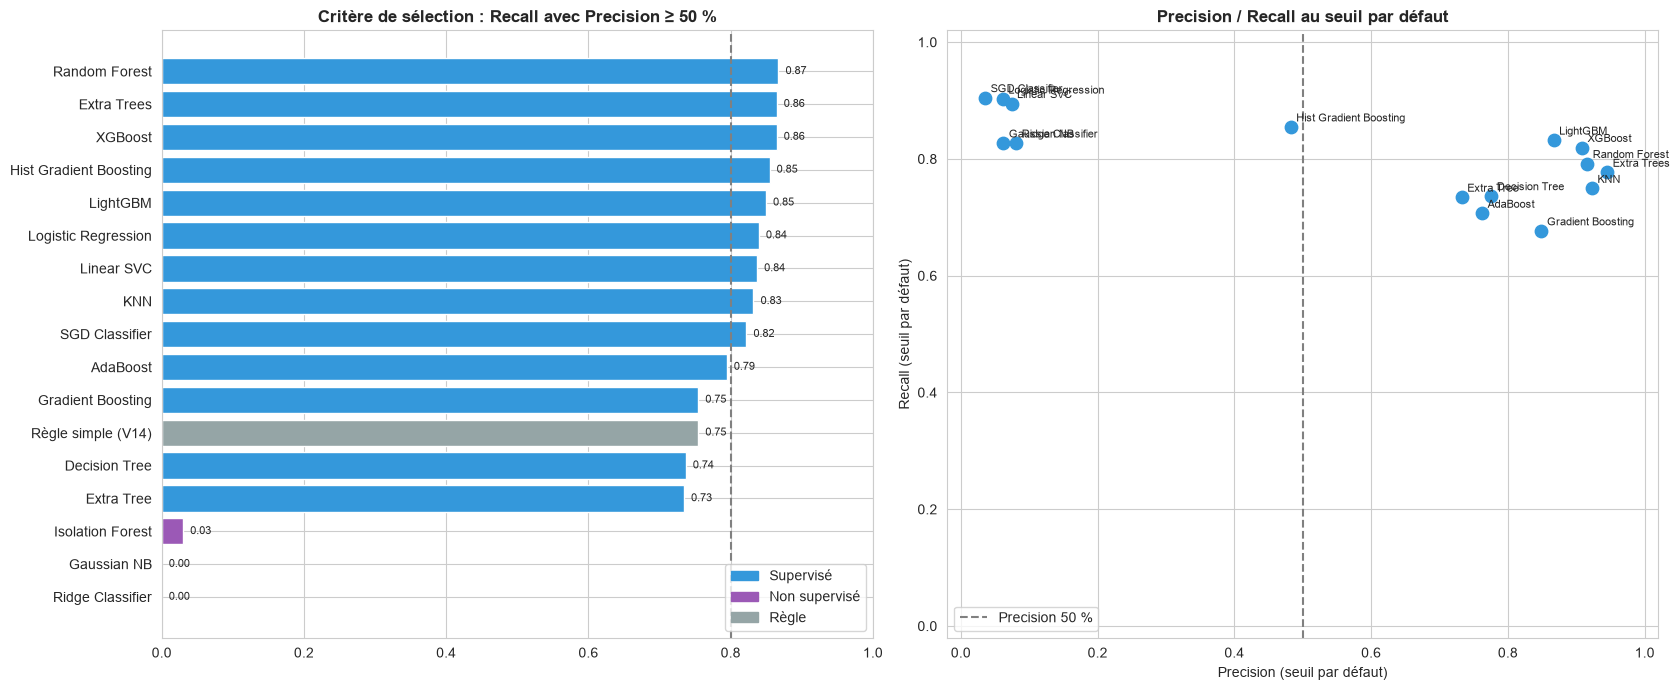

🏆 Meilleur modèle supervisé : Random Forest — Recall @ P≥50% = 0.867, PR-AUC = 0.846


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

ordre = comparaison.sort_values("Recall @ P≥50%")
couleurs = {"Supervisé": "#3498db", "Non supervisé": "#9b59b6", "Règle": "#95a5a6"}
axes[0].barh(ordre["Modèle"], ordre["Recall @ P≥50%"], color=[couleurs[t] for t in ordre["Type"]])
axes[0].axvline(0.80, color="gray", ls="--", label="Objectif recall 80 %")
axes[0].set_xlim(0, 1)
axes[0].set_title("Critère de sélection : Recall avec Precision ≥ 50 %", fontweight="bold")
for i, v in enumerate(ordre["Recall @ P≥50%"]):
    axes[0].text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8)
from matplotlib.patches import Patch
axes[0].legend(handles=[Patch(color=c, label=t) for t, c in couleurs.items()], loc="lower right")

sup = comparaison[comparaison["Type"] == "Supervisé"]
axes[1].scatter(sup["Precision (seuil défaut)"], sup["Recall (seuil défaut)"], s=80, color="#3498db")
for _, r in sup.iterrows():
    axes[1].annotate(r["Modèle"], (r["Precision (seuil défaut)"], r["Recall (seuil défaut)"]),
                     fontsize=8, xytext=(4, 4), textcoords="offset points")
axes[1].axvline(MIN_PRECISION, color="gray", ls="--", label="Precision 50 %")
axes[1].set_xlabel("Precision (seuil par défaut)")
axes[1].set_ylabel("Recall (seuil par défaut)")
axes[1].set_xlim(-0.02, 1.02)
axes[1].set_ylim(-0.02, 1.02)
axes[1].set_title("Precision / Recall au seuil par défaut", fontweight="bold")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.show()

supervises = comparaison[comparaison["Type"] == "Supervisé"]
MEILLEUR_NOM = supervises.iloc[0]["Modèle"]
print(f"🏆 Meilleur modèle supervisé : {MEILLEUR_NOM} — Recall @ P≥50% = {supervises.iloc[0]['Recall @ P≥50%']:.3f}, "
      f"PR-AUC = {supervises.iloc[0]['PR-AUC']:.3f}")

### Lecture du classement

**1. Trois modèles en tête, pratiquement à égalité.**

| Rang | Modèle | Recall @ P ≥ 50 % | PR-AUC |
|---|---|---|---|
| 1 | **Random Forest** | **0,867** | 0,846 |
| 2 | Extra Trees | 0,865 | **0,851** |
| 3 | XGBoost | 0,865 | 0,843 |
| 4 | Hist Gradient Boosting | 0,855 | 0,737 |
| 5 | LightGBM | 0,850 | 0,824 |

L'écart entre les trois premiers est de 0,002, soit **une seule fraude** sur les quelque 400 du train. Random Forest est retenu car il est premier sur notre critère principal. Mais Extra Trees a la meilleure PR-AUC et XGBoost est beaucoup plus rapide (11 s contre 97 s) : ces trois modèles sont des choix équivalents.

**2. Les bons modèles battent nettement la règle simple.** La règle « V14 très bas » détecte 75,4 % des fraudes à précision ≥ 50 %. Les meilleurs modèles en détectent **86,7 %**, soit 11 points de plus. En revanche, un arbre de décision seul (0,737) fait **moins bien** que cette règle d'une ligne.

**3. Sans étiquettes, on ne trouve presque rien.** L'Isolation Forest, qui cherche les transactions « bizarres » sans savoir lesquelles sont des fraudes, n'atteint que 3 % de recall. Les fraudes ne sont pas simplement des transactions rares : il faut apprendre à partir d'exemples étiquetés.

**4. Les modèles à éviter :**
- **Ridge Classifier et Gaussian Naive Bayes** n'atteignent **jamais** 50 % de précision, quel que soit le seuil.
- **Gradient Boosting** (version classique, 0,754) est faible et c'est le plus lent (404 s). Il n'a pas de pondération des classes. Hist Gradient Boosting, LightGBM et XGBoost, qui en ont une, font bien mieux.
- **Les arbres seuls** (Decision Tree, Extra Tree) restent loin derrière les **forêts** (Random Forest, Extra Trees) : faire voter des centaines d'arbres stabilise les prédictions.

**5. La Logistic Regression reste un bon modèle de référence** (0,840) : simple, rapide et lisible. C'est pourquoi elle sert de modèle de base en phase 5.

## 4.5 Gestion du déséquilibre : quelle stratégie ?

Pour le modèle retenu, nous comparons quatre façons de traiter le déséquilibre :

| Stratégie | Principe | Risque |
|---|---|---|
| **Aucune correction** | on entraîne sur les données telles quelles | le modèle peut ignorer la classe rare |
| **Pondération des classes** | chaque fraude pèse plus lourd dans l'apprentissage | aucun, si le modèle le permet |
| **Sous-échantillonnage** | on retire des transactions normales au hasard (ici jusqu'à 10 normales pour 1 fraude) | on jette beaucoup d'information |
| **SMOTE** | on crée des fraudes **synthétiques** en interpolant entre fraudes proches (jusqu'à 1 fraude pour 10 normales) | les fausses fraudes peuvent ne pas ressembler aux vraies |

**Règle d'or** : le rééchantillonnage ne doit être appliqué **que sur la partie entraînement de chaque pli**, jamais sur les données d'évaluation. Sinon, on évalue le modèle sur des fraudes artificielles. Le Pipeline d'imbalanced-learn le garantit.

In [18]:
def sans_ponderation(modele):
    # Copie du modèle sans correction interne du déséquilibre
    m = clone(modele)
    params = m.get_params()
    if "class_weight" in params:
        m.set_params(class_weight=None)
    if "scale_pos_weight" in params:
        m.set_params(scale_pos_weight=1)
    return m

base = modeles[MEILLEUR_NOM]
strategies = {
    "Aucune correction": creer_pipeline(sans_ponderation(base)),
    "Pondération des classes": creer_pipeline(clone(base)),
    "Sous-échantillonnage (1:10)": creer_pipeline(sans_ponderation(base),
                                                   RandomUnderSampler(sampling_strategy=0.1, random_state=RANDOM_STATE)),
    "SMOTE (1:10)": creer_pipeline(sans_ponderation(base), SMOTE(sampling_strategy=0.1, random_state=RANDOM_STATE)),
}

res_strat, scores_strat = [], {}
for nom, pipe in strategies.items():
    debut = time.time()
    methode = "predict_proba" if hasattr(pipe, "predict_proba") else "decision_function"
    s = cross_val_predict(pipe, X_train, y_train, cv=cv5, method=methode, n_jobs=N_JOBS)
    s = s[:, 1] if s.ndim == 2 else s
    scores_strat[nom] = s
    r = ligne_resultat(nom, "", y_train, s, 0.5 if methode == "predict_proba" else 0.0, time.time() - debut)
    res_strat.append(r)
    print(f"✓ {nom:<28} Recall@P≥50% = {r['Recall @ P≥50%']:.3f} | PR-AUC = {r['PR-AUC']:.3f} | {r['Durée (s)']:.0f} s")

comp_strat = (pd.DataFrame(res_strat).drop(columns="Type").rename(columns={"Modèle": "Stratégie"})
              .sort_values(["Recall @ P≥50%", "PR-AUC"], ascending=False).reset_index(drop=True))
display(comp_strat.style.format(precision=3))

STRATEGIE = comp_strat.iloc[0]["Stratégie"]
print(f"→ Stratégie retenue pour {MEILLEUR_NOM} : {STRATEGIE}")

✓ Aucune correction            Recall@P≥50% = 0.860 | PR-AUC = 0.839 | 243 s
✓ Pondération des classes      Recall@P≥50% = 0.867 | PR-AUC = 0.846 | 101 s
✓ Sous-échantillonnage (1:10)  Recall@P≥50% = 0.855 | PR-AUC = 0.730 | 7 s
✓ SMOTE (1:10)                 Recall@P≥50% = 0.867 | PR-AUC = 0.855 | 255 s


,Stratégie,Recall @ P≥50%,PR-AUC,ROC-AUC,Recall (seuil défaut),Precision (seuil défaut),F1 (seuil défaut),F2 (seuil défaut),Durée (s)
0,SMOTE (1:10),0.867,0.855,0.974,0.825,0.894,0.858,0.838,255.200
1,Pondération des classes,0.867,0.846,0.960,0.792,0.916,0.849,0.814,100.700
2,Aucune correction,0.860,0.839,0.946,0.782,0.931,0.850,0.808,243.100
3,Sous-échantillonnage (1:10),0.855,0.730,0.973,0.850,0.567,0.680,0.773,7.100


→ Stratégie retenue pour Random Forest : SMOTE (1:10)


### Lecture : quelle stratégie pour Random Forest ?

| Stratégie | Recall @ P ≥ 50 % | PR-AUC | Durée |
|---|---|---|---|
| **SMOTE (1:10)** ✅ | **0,867** | **0,855** | 255 s |
| Pondération des classes | 0,867 | 0,846 | 101 s |
| Aucune correction | 0,860 | 0,839 | 243 s |
| Sous-échantillonnage (1:10) | 0,855 | 0,730 | 7 s |

- **SMOTE et la pondération sont à égalité sur le recall.** SMOTE l'emporte grâce à une PR-AUC un peu meilleure (0,855 contre 0,846), il est donc retenu. L'écart reste faible et SMOTE est 2,5 fois plus lent : la pondération serait aussi un choix raisonnable.
- **Random Forest supporte déjà bien le déséquilibre** : sans aucune correction, il atteint 0,860. Les corrections apportent environ 3 fraudes de plus sur 400.
- **Le sous-échantillonnage est très rapide (7 s) mais dégrade la PR-AUC (0,730).** Il jette environ 98 % des transactions normales : le modèle apprend mal à quoi ressemble une transaction normale, d'où beaucoup de fausses alertes (précision de 57 % au seuil 0,5).

**Pas de fuite d'information :** SMOTE est placé **dans** le Pipeline. Il n'est appliqué qu'aux plis d'entraînement : les fausses fraudes ne se retrouvent jamais dans les données d'évaluation.

## 4.6 Optimisation des hyperparamètres

Les modèles ont été comparés avec leurs **réglages par défaut**. Nous cherchons maintenant de meilleurs **hyperparamètres** pour le modèle retenu, avec sa stratégie de déséquilibre.

**Méthode : `RandomizedSearchCV`**. Au lieu de tester toutes les combinaisons (des centaines), on en tire **10 au hasard**, chacune évaluée en validation croisée stratifiée à 3 plis.

**Score optimisé : la PR-AUC.** C'est une mesure globale, qui ne dépend pas d'un seuil et qui est plus stable que le recall à précision fixée quand il y a peu de fraudes par pli. Le recall à précision ≥ 50 % est suivi en parallèle.

Le modèle optimisé est ensuite comparé au modèle par défaut **avec la même validation croisée à 5 plis**. On ne garde l'optimisation que si elle améliore le critère de sélection.

⏱️ Comptez **de 5 minutes à 1 heure** selon le modèle (environ 1 heure pour Random Forest avec SMOTE).

In [19]:
grilles = {
    "Logistic Regression": {"model__C": [0.001, 0.01, 0.1, 1, 10, 100], "model__class_weight": [None, "balanced"]},
    "Ridge Classifier": {"model__alpha": [0.01, 0.1, 1, 10, 100], "model__class_weight": [None, "balanced"]},
    "SGD Classifier": {"model__loss": ["hinge", "log_loss", "modified_huber"], "model__alpha": [1e-5, 1e-4, 1e-3],
                       "model__class_weight": [None, "balanced"]},
    "KNN": {"model__n_neighbors": [1, 3, 5, 7, 11], "model__weights": ["uniform", "distance"]},
    "Decision Tree": {"model__max_depth": [None, 5, 10, 20], "model__min_samples_leaf": [1, 5, 10, 20],
                      "model__criterion": ["gini", "entropy"], "model__class_weight": [None, "balanced"]},
    "Extra Tree": {"model__max_depth": [None, 5, 10, 20], "model__min_samples_leaf": [1, 5, 10, 20],
                   "model__criterion": ["gini", "entropy"], "model__class_weight": [None, "balanced"]},
    "Random Forest": {"model__n_estimators": [100, 200, 300], "model__max_depth": [None, 10, 20, 30],
                      "model__min_samples_split": [2, 5, 10], "model__min_samples_leaf": [1, 2, 4],
                      "model__max_features": ["sqrt", 0.5],
                      "model__class_weight": [None, "balanced", "balanced_subsample"]},
    "Extra Trees": {"model__n_estimators": [100, 200, 300], "model__max_depth": [None, 10, 20, 30],
                    "model__min_samples_split": [2, 5, 10], "model__min_samples_leaf": [1, 2, 4],
                    "model__max_features": ["sqrt", 0.5],
                    "model__class_weight": [None, "balanced", "balanced_subsample"]},
    "AdaBoost": {"model__n_estimators": [50, 100, 200, 400], "model__learning_rate": [0.1, 0.5, 1.0]},
    "Gradient Boosting": {"model__n_estimators": [100, 200], "model__learning_rate": [0.05, 0.1, 0.2],
                          "model__max_depth": [2, 3, 4], "model__subsample": [0.8, 1.0]},
    "Hist Gradient Boosting": {"model__learning_rate": [0.03, 0.05, 0.1, 0.2], "model__max_iter": [100, 200, 400],
                               "model__max_leaf_nodes": [15, 31, 63], "model__l2_regularization": [0, 0.1, 1],
                               "model__class_weight": [None, "balanced"]},
    "LightGBM": {"model__n_estimators": [200, 400, 800], "model__learning_rate": [0.02, 0.05, 0.1],
                 "model__num_leaves": [15, 31, 63], "model__min_child_samples": [10, 20, 50],
                 "model__subsample": [0.8, 1.0], "model__colsample_bytree": [0.6, 0.8, 1.0],
                 "model__class_weight": [None, "balanced"]},
    "XGBoost": {"model__n_estimators": [200, 400, 800], "model__learning_rate": [0.02, 0.05, 0.1],
                "model__max_depth": [3, 4, 6, 8], "model__min_child_weight": [1, 3, 5],
                "model__subsample": [0.8, 1.0], "model__colsample_bytree": [0.6, 0.8, 1.0],
                "model__scale_pos_weight": [1, 10, RATIO]},
    "Gaussian NB": {"model__var_smoothing": [1e-11, 1e-10, 1e-9, 1e-8, 1e-7, 1e-6, 1e-5]},
    "Linear SVC": {"model__C": [0.001, 0.01, 0.1, 1, 10], "model__class_weight": [None, "balanced"]},
}

grille = dict(grilles[MEILLEUR_NOM])
if STRATEGIE != "Pondération des classes":
    # la stratégie retenue fixe déjà la façon de traiter le déséquilibre
    grille = {k: v for k, v in grille.items() if "class_weight" not in k and "scale_pos_weight" not in k}

scorer_recall_p50 = make_scorer(lambda yt, s: recall_a_precision(yt, s)[0],
                                response_method=("predict_proba", "decision_function"))
n_iter = min(10, len(ParameterGrid(grille)))
recherche = RandomizedSearchCV(
    strategies[STRATEGIE],
    param_distributions=grille,
    n_iter=n_iter,
    scoring={"pr_auc": "average_precision", "recall_p50": scorer_recall_p50},
    refit="pr_auc",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
debut = time.time()
recherche.fit(X_train, y_train)
print(f"Recherche terminée en {(time.time() - debut) / 60:.1f} min ({n_iter} combinaisons × 3 plis)")
print(f"Meilleurs hyperparamètres : {recherche.best_params_}")
print(f"PR-AUC (CV 3 plis) : {recherche.best_score_:.3f}")
display(pd.DataFrame(recherche.cv_results_).sort_values("rank_test_pr_auc")
        [["params", "mean_test_pr_auc", "mean_test_recall_p50"]].head(5))

Recherche terminée en 58.4 min (10 combinaisons × 3 plis)
Meilleurs hyperparamètres : {'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 30}
PR-AUC (CV 3 plis) : 0.855


,params,mean_test_pr_auc,mean_test_recall_p50
6,"{'model__n_estimators': 300, 'model__min_sampl...",0.855183,0.874687
5,"{'model__n_estimators': 100, 'model__min_sampl...",0.854073,0.872180
4,"{'model__n_estimators': 100, 'model__min_sampl...",0.849625,0.869674
9,"{'model__n_estimators': 200, 'model__min_sampl...",0.849360,0.867168
3,"{'model__n_estimators': 100, 'model__min_sampl...",0.849312,0.869674


In [20]:
pipe_opt = recherche.best_estimator_
methode = "predict_proba" if hasattr(pipe_opt, "predict_proba") else "decision_function"
s_opt = cross_val_predict(pipe_opt, X_train, y_train, cv=cv5, method=methode, n_jobs=N_JOBS)
s_opt = s_opt[:, 1] if s_opt.ndim == 2 else s_opt

s_def = scores_strat[STRATEGIE]
r_def, r_opt = recall_a_precision(y_train, s_def)[0], recall_a_precision(y_train, s_opt)[0]
ap_def, ap_opt = average_precision_score(y_train, s_def), average_precision_score(y_train, s_opt)
print(f"Paramètres par défaut : Recall@P≥50% = {r_def:.3f} | PR-AUC = {ap_def:.3f}")
print(f"Paramètres optimisés  : Recall@P≥50% = {r_opt:.3f} | PR-AUC = {ap_opt:.3f}")

if (r_opt, ap_opt) >= (r_def, ap_def):
    pipeline_final, scores_train_oof, PARAMS_RETENUS = pipe_opt, s_opt, recherche.best_params_
    print("→ On garde les hyperparamètres optimisés.")
else:
    pipeline_final, scores_train_oof, PARAMS_RETENUS = strategies[STRATEGIE], s_def, "paramètres par défaut"
    print("→ L'optimisation n'améliore pas le critère : on garde les paramètres par défaut.")

Paramètres par défaut : Recall@P≥50% = 0.867 | PR-AUC = 0.855
Paramètres optimisés  : Recall@P≥50% = 0.870 | PR-AUC = 0.855
→ On garde les hyperparamètres optimisés.


## 4.7 Choix du seuil : coût et capacité de vérification

Le modèle produit un **score de fraude**. La décision dépend du **seuil** :
- seuil **haut** → peu d'alertes, mais des fraudes ratées ;
- seuil **bas** → beaucoup de fraudes détectées, mais plus d'alertes à vérifier.

Le seuil de 0,5 n'a **aucune justification métier**. Nous le choisissons à partir des hypothèses de la phase 1 :

$$ \text{Coût}(\text{seuil}) = \text{Nb d'alertes} \times 5\,€ + \sum \text{montants des fraudes ratées} $$

**Seuil d'alerte** = celui qui **minimise le coût total**, sous la contrainte de **ne pas dépasser 500 alertes par jour**.

Nous définissons aussi un **seuil de blocage**, plus haut : au-delà, le modèle est sûr à au moins 90 % et la transaction est **bloquée directement**, sans attendre un analyste. Cela donne la décision en 3 niveaux décrite en phase 1 :

| Score | Décision |
|---|---|
| ≥ seuil de blocage | 🔴 **Bloquer** la transaction |
| entre les deux seuils | 🟠 **Vérifier** : un analyste contacte le client |
| < seuil d'alerte | 🟢 **Accepter** |

Tous les seuils sont choisis sur les prédictions hors échantillon du **train**, jamais sur le test.

,Seuil,Valeur,Recall,Precision,Alertes / jour,Coût total (train)
0,"Par défaut (0,5)",0.5000,0.835,0.865,242,"14,325 €"
1,Recall max à Precision ≥ 50 %,0.1387,0.870,0.510,427,"13,928 €"
2,Coût minimal sous capacité ✅,0.2330,0.862,0.727,297,"13,613 €"
3,Blocage (Precision ≥ 90 %),0.6137,0.817,0.908,225,"14,730 €"


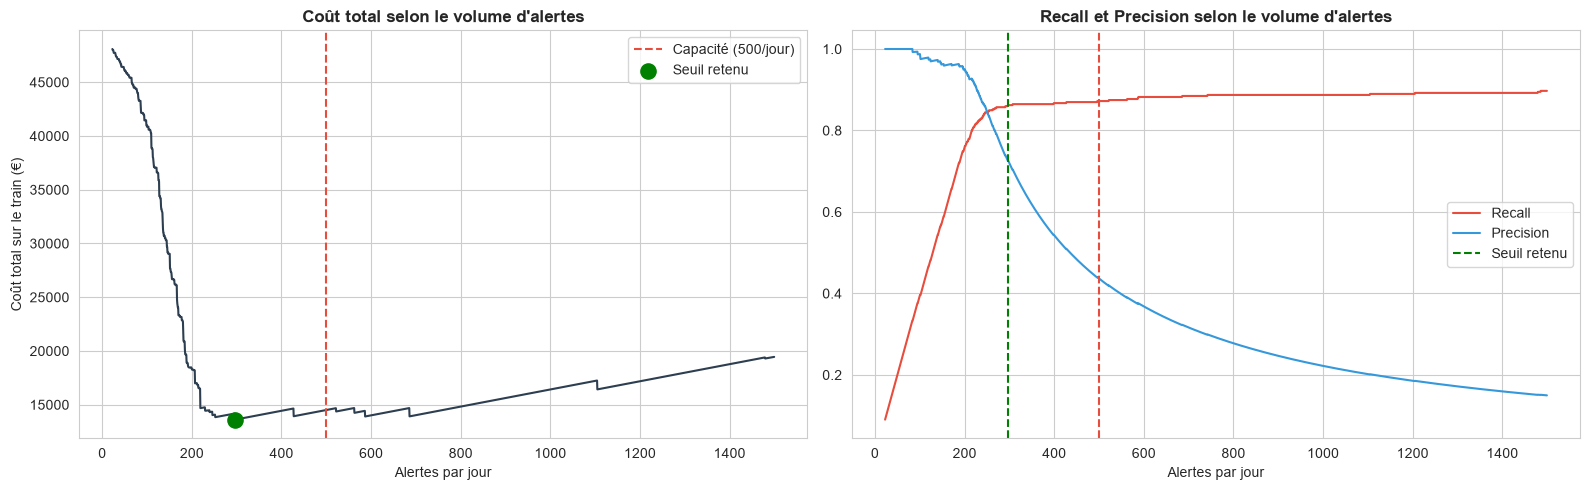

In [21]:
def courbe_cout(y_true, scores, montants, cout_alerte=COUT_VERIFICATION):
    # Coût total et volume d'alertes pour chaque seuil possible
    ordre = np.argsort(-scores, kind="stable")
    s, yy, a = scores[ordre], np.asarray(y_true)[ordre], np.asarray(montants)[ordre]
    fin = np.r_[np.where(np.diff(s) != 0)[0], len(s) - 1]       # dernière position de chaque valeur de score
    k = fin + 1                                                  # nombre d'alertes si seuil = s[fin]
    tp = np.cumsum(yy)[fin]
    bloque = np.cumsum(a * yy)[fin]
    total = (a * yy).sum()
    return pd.DataFrame({
        "seuil": s[fin], "alertes": k, "alertes_par_jour": k / len(s) * TX_PAR_JOUR,
        "recall": tp / yy.sum(), "precision": tp / k,
        "cout_total": k * cout_alerte + (total - bloque),
    })


montants_train = X_train["Amount"].to_numpy()
courbe = courbe_cout(y_train, scores_train_oof, montants_train)
admissibles = courbe[courbe["alertes_par_jour"] <= CAPACITE_ALERTES_JOUR]
optimum = admissibles.loc[admissibles["cout_total"].idxmin()]

SEUIL = float(optimum["seuil"])
SEUIL_P50 = recall_a_precision(y_train, scores_train_oof)[1]
_seuil_90 = recall_a_precision(y_train, scores_train_oof, PRECISION_BLOCAGE)[1]
SEUIL_BLOCAGE = SEUIL if np.isnan(_seuil_90) else max(_seuil_90, SEUIL)
methode_finale = "predict_proba" if hasattr(pipeline_final, "predict_proba") else "decision_function"
SEUIL_DEFAUT = 0.5 if methode_finale == "predict_proba" else 0.0

def resume_seuil(nom, seuil):
    pred = (scores_train_oof >= seuil).astype(int)
    m = metriques(y_train, pred)
    cout = pred.sum() * COUT_VERIFICATION + montants_train[(y_train.to_numpy() == 1) & (pred == 0)].sum()
    return {"Seuil": nom, "Valeur": seuil, "Recall": m["Recall"], "Precision": m["Precision"],
            "Alertes / jour": pred.sum() / len(pred) * TX_PAR_JOUR, "Coût total (train)": cout}

tableau_seuils = pd.DataFrame([
    resume_seuil("Par défaut (0,5)", SEUIL_DEFAUT),
    resume_seuil("Recall max à Precision ≥ 50 %", SEUIL_P50),
    resume_seuil("Coût minimal sous capacité ✅", SEUIL),
    resume_seuil("Blocage (Precision ≥ 90 %)", SEUIL_BLOCAGE),
])
display(tableau_seuils.style.format({"Valeur": "{:.4f}", "Recall": "{:.3f}", "Precision": "{:.3f}",
                                     "Alertes / jour": "{:.0f}", "Coût total (train)": "{:,.0f} €"}))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
c = courbe[courbe["alertes_par_jour"] <= 3 * CAPACITE_ALERTES_JOUR]
axes[0].plot(c["alertes_par_jour"], c["cout_total"], color="#2c3e50")
axes[0].axvline(CAPACITE_ALERTES_JOUR, color="#e74c3c", ls="--", label=f"Capacité ({CAPACITE_ALERTES_JOUR}/jour)")
axes[0].scatter([optimum["alertes_par_jour"]], [optimum["cout_total"]], s=120, color="green", zorder=5,
                label="Seuil retenu")
axes[0].set_xlabel("Alertes par jour")
axes[0].set_ylabel("Coût total sur le train (€)")
axes[0].set_title("Coût total selon le volume d'alertes", fontweight="bold")
axes[0].legend()

axes[1].plot(c["alertes_par_jour"], c["recall"], label="Recall", color="#e74c3c")
axes[1].plot(c["alertes_par_jour"], c["precision"], label="Precision", color="#3498db")
axes[1].axvline(CAPACITE_ALERTES_JOUR, color="#e74c3c", ls="--")
axes[1].axvline(optimum["alertes_par_jour"], color="green", ls="--", label="Seuil retenu")
axes[1].set_xlabel("Alertes par jour")
axes[1].set_title("Recall et Precision selon le volume d'alertes", fontweight="bold")
axes[1].legend()
plt.tight_layout()
plt.show()

### Sensibilité aux hypothèses

Le coût d'une vérification (5 €) et la capacité (500 alertes par jour) sont des hypothèses. Voyons comment le seuil choisi évolue si on les change.

In [22]:
lignes = []
for cout in [1, 5, 20, 50]:
    for capacite in [250, 500, 1000]:
        cb = courbe_cout(y_train, scores_train_oof, montants_train, cout_alerte=cout)
        adm = cb[cb["alertes_par_jour"] <= capacite]
        o = adm.loc[adm["cout_total"].idxmin()]
        lignes.append({"Coût d'une alerte (€)": cout, "Capacité (alertes/jour)": capacite,
                       "Seuil": o["seuil"], "Alertes/jour": o["alertes_par_jour"],
                       "Recall": o["recall"], "Precision": o["precision"]})
sensibilite = pd.DataFrame(lignes)
display(sensibilite.style.format({"Seuil": "{:.4f}", "Alertes/jour": "{:.0f}", "Recall": "{:.3f}", "Precision": "{:.3f}"}))

,Coût d'une alerte (€),Capacité (alertes/jour),Seuil,Alertes/jour,Recall,Precision
0,1,250,0.4824,246,0.845,0.860
1,1,500,0.1387,427,0.870,0.510
2,1,1000,0.0960,686,0.885,0.323
3,5,250,0.4824,246,0.845,0.860
4,5,500,0.2330,297,0.862,0.727
5,5,1000,0.2330,297,0.862,0.727
6,20,250,0.4824,246,0.845,0.860
7,20,500,0.4327,252,0.847,0.841
8,20,1000,0.4327,252,0.847,0.841
9,50,250,0.6686,219,0.807,0.923


### Lecture : quel seuil d'alerte ?

Sur les prédictions hors échantillon du train :

| Seuil | Valeur | Recall | Precision | Alertes / jour | Coût |
|---|---|---|---|---|---|
| Par défaut | 0,500 | 0,835 | 0,865 | 242 | 14 325 € |
| Recall max à Precision ≥ 50 % | 0,139 | 0,870 | 0,510 | 427 | 13 928 € |
| **Coût minimal sous capacité** ✅ | **0,233** | **0,862** | **0,727** | **297** | **13 613 €** |
| Blocage (Precision ≥ 90 %) | 0,614 | 0,817 | 0,908 | 225 | — |

- **Le seuil retenu (0,233) est le moins coûteux.** Il détecte plus de fraudes que le seuil par défaut (86,2 % contre 83,5 %) avec 297 alertes par jour, bien en dessous de la capacité de 500.
- **Aller chercher le recall maximum ne vaut pas le coup.** Le seuil 0,139 détecte environ 3 fraudes de plus, mais ajoute 130 alertes par jour et coûte plus cher au total.
- **Décision en 3 niveaux :** score < 0,233 → 🟢 accepter ; entre 0,233 et 0,614 → 🟠 vérifier ; score ≥ 0,614 → 🔴 bloquer. Au-dessus de 0,614, 9 alertes sur 10 sont de vraies fraudes, ce qui justifie un blocage automatique.

**Sensibilité aux hypothèses.** Le seuil dépend surtout du **coût d'une alerte** : 0,14 à 1 €, 0,23 à 5 €, 0,43 à 20 € et 0,67 à 50 €. Plus une vérification coûte cher, plus on devient exigeant avant d'alerter. La capacité ne compte que lorsqu'elle est serrée : avec 250 alertes par jour, le seuil monte à 0,48. **Le seuil est donc une décision métier** : il devra être recalculé si la banque fournit ses vrais coûts.

---

# PHASE 5 — EVALUATION (Évaluation)

## 5.1 Évaluation finale sur le jeu de test

Le modèle est entraîné sur **tout le train**, puis évalué **une seule fois** sur les 20 % de transactions les plus récentes, jamais utilisées jusqu'ici. Nous comparons :
- le **seuil retenu** (coût minimal sous capacité) ;
- le seuil par défaut (0,5), pour montrer l'apport du choix du seuil ;
- la **règle simple** (V14) et la **Logistic Regression** (modèle de base), pour montrer l'apport du modèle.

In [23]:
if "model__n_jobs" in pipeline_final.get_params():
    pipeline_final.set_params(model__n_jobs=-1)
debut = time.time()
pipeline_final.fit(X_train, y_train)
print(f"Modèle final ({MEILLEUR_NOM}, {STRATEGIE}) entraîné en {time.time() - debut:.0f} s")
if "model__n_jobs" in pipeline_final.get_params():
    pipeline_final.set_params(model__n_jobs=1)   # plus rapide pour une transaction à la fois

scores_test = scores_fraude(pipeline_final, X_test)
y_pred = (scores_test >= SEUIL).astype(int)
y_pred_defaut = (scores_test >= SEUIL_DEFAUT).astype(int)

# Modèle de base : Logistic Regression, seuil choisi de la même façon (coût sous capacité)
base_lr = creer_pipeline(modeles["Logistic Regression"]).fit(X_train, y_train)
s_lr_test = scores_fraude(base_lr, X_test)
cb_lr = courbe_cout(y_train, scores_oof["Logistic Regression"], montants_train)
seuil_lr = cb_lr[cb_lr["alertes_par_jour"] <= CAPACITE_ALERTES_JOUR].sort_values("cout_total").iloc[0]["seuil"]

score_regle_test = -X_test["V14"].to_numpy()

res_test = pd.DataFrame({
    f"{MEILLEUR_NOM} — seuil retenu": metriques(y_test, y_pred, scores_test),
    f"{MEILLEUR_NOM} — seuil 0,5": metriques(y_test, y_pred_defaut, scores_test),
    "Modèle de base (Logistic Reg.)": metriques(y_test, (s_lr_test >= seuil_lr).astype(int), s_lr_test),
    "Règle simple (V14)": metriques(y_test, (score_regle_test >= SEUIL_REGLE).astype(int), score_regle_test),
})
duree_test_jours = (X_test["Time"].max() - X_test["Time"].min()) / 86400
for col, pred in zip(res_test.columns, [y_pred, y_pred_defaut, (s_lr_test >= seuil_lr).astype(int),
                                         (score_regle_test >= SEUIL_REGLE).astype(int)]):
    rate = X_test["Amount"].to_numpy()[(y_test.to_numpy() == 1) & (pred == 0)].sum()
    res_test.loc["Alertes / jour", col] = pred.sum() / duree_test_jours
    res_test.loc["Coût total (€)", col] = pred.sum() * COUT_VERIFICATION + rate
display(res_test.style.format(precision=3))

print("\nRapport de classification (seuil retenu) :")
print(classification_report(y_test, y_pred, target_names=["Normale", "Fraude"], digits=3))

Modèle final (Random Forest, SMOTE (1:10)) entraîné en 149 s


,Random Forest — seuil retenu,"Random Forest — seuil 0,5",Modèle de base (Logistic Reg.),Règle simple (V14)
Accuracy,0.999,1.000,0.999,0.999
Precision,0.532,0.848,0.733,0.543
Recall,0.797,0.757,0.743,0.676
F1,0.638,0.800,0.738,0.602
F2,0.725,0.773,0.741,0.644
FPR,0.001,0.000,0.000,0.001
TP,59.000,56.000,55.000,50.000
FN,15.000,18.000,19.000,24.000
FP,52.000,10.000,20.000,42.000
TN,56620.000,56662.000,56652.000,56630.000



Rapport de classification (seuil retenu) :
              precision    recall  f1-score   support

     Normale      1.000     0.999     0.999     56672
      Fraude      0.532     0.797     0.638        74

    accuracy                          0.999     56746
   macro avg      0.766     0.898     0.819     56746
weighted avg      0.999     0.999     0.999     56746



### Interprétation des résultats sur le jeu de test

Le test couvre les **7,7 dernières heures** (de 40,3 h à 48 h) : 56 746 transactions jamais vues, dont **74 fraudes**.

| | **Random Forest (seuil 0,233)** | Random Forest (seuil 0,5) | Logistic Regression | Règle V14 |
|---|---|---|---|---|
| Fraudes détectées | **59 / 74** | 56 / 74 | 55 / 74 | 50 / 74 |
| Fraudes ratées | **15** | 18 | 19 | 24 |
| Fausses alertes | 52 | 10 | 20 | 42 |
| **Recall** | **79,7 %** | 75,7 % | 74,3 % | 67,6 % |
| Precision | 53,2 % | 84,8 % | 73,3 % | 54,3 % |
| PR-AUC | **0,815** | 0,815 | 0,757 | 0,639 |
| Alertes / jour | 348 | 207 | 235 | 288 |
| **Coût total** | **2 953 €** | 2 968 € | 3 014 € | 4 626 € |

**1. Notre modèle est le meilleur sur le recall et sur le coût.** Il détecte 4 fraudes de plus que la Logistic Regression et 9 de plus que la règle simple, pour un coût inférieur de 36 % à celui de la règle.

**2. Le gain du seuil abaissé est réel mais modeste.** Par rapport au seuil 0,5, il détecte 3 fraudes de plus au prix de 42 fausses alertes supplémentaires. Avec nos hypothèses de coût, les deux seuils coûtent presque la même chose (15 € d'écart). Le seuil retenu respecte la priorité donnée au recall.

**3. La précision a baissé par rapport au train** (53 % contre 73 %). La période de test contient proportionnellement moins de fraudes (0,13 % contre 0,18 % dans le train) : à seuil égal, la part de vraies fraudes parmi les alertes diminue. C'est un effet de l'évolution dans le temps, que seul un découpage temporel permet de voir.

**4. Impact financier.** Sans modèle, les 74 fraudes du test seraient passées : **7 728 € perdus**. Avec le modèle, le coût total (pertes + vérifications) tombe à **2 953 €**, soit **62 % d'économie**. Le modèle bloque **69 % du montant fraudé** (5 330 €).

**Bilan par rapport aux critères de réussite fixés en phase 1 :**

| Critère | Objectif | Résultat (test) | |
|---|---|---|---|
| Recall | > 80 % | **79,7 %** (IC 95 % : 70 % à 89 %) | ⚠️ juste en dessous : une fraude détectée de plus donnerait 81,1 % |
| Volume d'alertes | ≤ 500 / jour | **348** | ✅ |
| PR-AUC | > 0,75 | **0,815** | ✅ |
| Temps de prédiction | < 10 ms | **37 ms** (phase 6) | ❌ |

## 5.2 Matrices de confusion, courbes ROC et Precision-Recall

- **TP** : fraudes détectées — **TN** : transactions normales acceptées
- **FP** : fausses alertes — **FN** : fraudes ratées, **l'erreur la plus coûteuse**

La **courbe Precision-Recall** est la plus informative sur des données déséquilibrées. Le point vert marque notre seuil de fonctionnement.

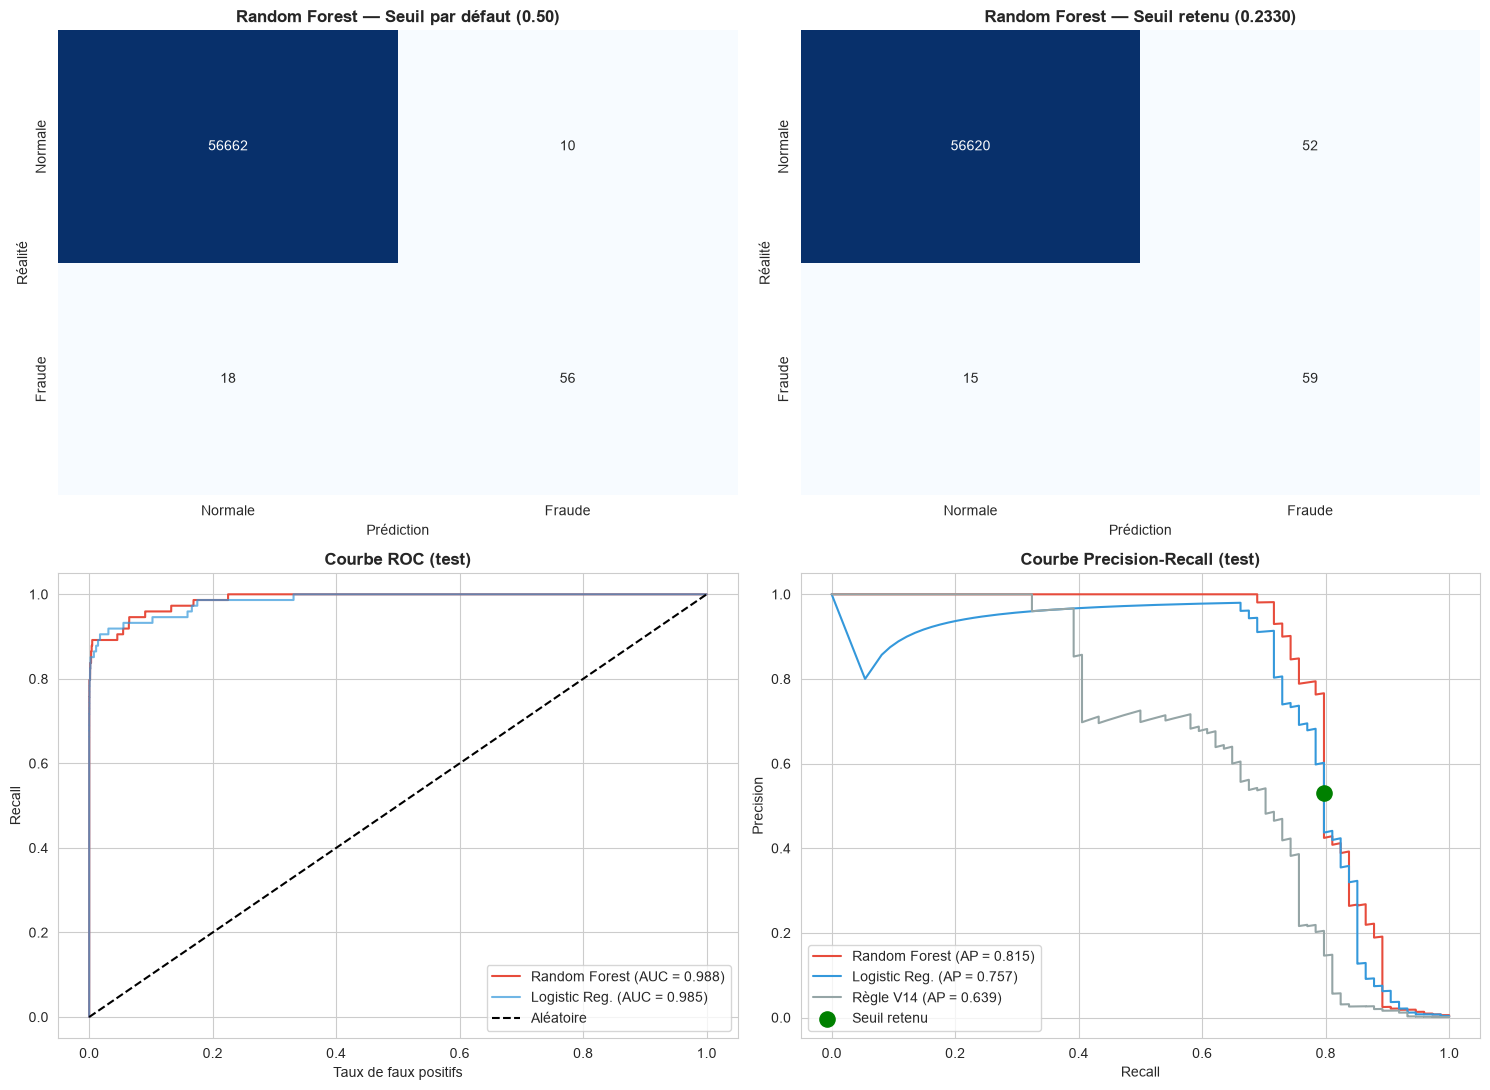

Seuil retenu : 59 fraudes détectées sur 74, 15 ratées, 52 fausses alertes sur 56,672 transactions normales


In [24]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for ax, pred, titre in [(axes[0, 0], y_pred_defaut, f"Seuil par défaut ({SEUIL_DEFAUT:.2f})"),
                        (axes[0, 1], y_pred, f"Seuil retenu ({SEUIL:.4f})")]:
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Normale", "Fraude"], yticklabels=["Normale", "Fraude"])
    ax.set_title(f"{MEILLEUR_NOM} — {titre}", fontweight="bold")
    ax.set_xlabel("Prédiction")
    ax.set_ylabel("Réalité")

fpr, tpr, _ = roc_curve(y_test, scores_test)
axes[1, 0].plot(fpr, tpr, color="#e74c3c", label=f"{MEILLEUR_NOM} (AUC = {roc_auc_score(y_test, scores_test):.3f})")
fpr_lr, tpr_lr, _ = roc_curve(y_test, s_lr_test)
axes[1, 0].plot(fpr_lr, tpr_lr, color="#3498db", alpha=0.7, label=f"Logistic Reg. (AUC = {roc_auc_score(y_test, s_lr_test):.3f})")
axes[1, 0].plot([0, 1], [0, 1], "k--", label="Aléatoire")
axes[1, 0].set_xlabel("Taux de faux positifs")
axes[1, 0].set_ylabel("Recall")
axes[1, 0].set_title("Courbe ROC (test)", fontweight="bold")
axes[1, 0].legend()

for s, nom, col in [(scores_test, MEILLEUR_NOM, "#e74c3c"), (s_lr_test, "Logistic Reg.", "#3498db"),
                    (score_regle_test, "Règle V14", "#95a5a6")]:
    p, r, _ = precision_recall_curve(y_test, s)
    axes[1, 1].plot(r, p, color=col, label=f"{nom} (AP = {average_precision_score(y_test, s):.3f})")
axes[1, 1].scatter([recall_score(y_test, y_pred)], [precision_score(y_test, y_pred)], s=120, color="green",
                   zorder=5, label="Seuil retenu")
axes[1, 1].set_xlabel("Recall")
axes[1, 1].set_ylabel("Precision")
axes[1, 1].set_title("Courbe Precision-Recall (test)", fontweight="bold")
axes[1, 1].legend(loc="lower left")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"Seuil retenu : {tp} fraudes détectées sur {tp + fn}, {fn} ratées, {fp} fausses alertes "
      f"sur {tn + fp:,} transactions normales")

## 5.3 Intervalles de confiance (bootstrap)

Le test ne contient qu'**une centaine de fraudes** : une seule fraude de plus ou de moins détectée fait varier le recall d'environ 1 point. Un chiffre seul (« recall 82 % ») donne donc une fausse impression de précision.

**Méthode du bootstrap** : on tire 1 000 fois, avec remise, un échantillon de la même taille que le test, et on recalcule les métriques à chaque fois. L'intervalle entre le 2,5e et le 97,5e percentile donne un **intervalle de confiance à 95 %**.

,Valeur (test),IC 95 % — bas,IC 95 % — haut
Recall,0.797,0.701,0.886
Precision,0.532,0.447,0.622
F1,0.638,0.558,0.714
PR-AUC,0.815,0.735,0.888


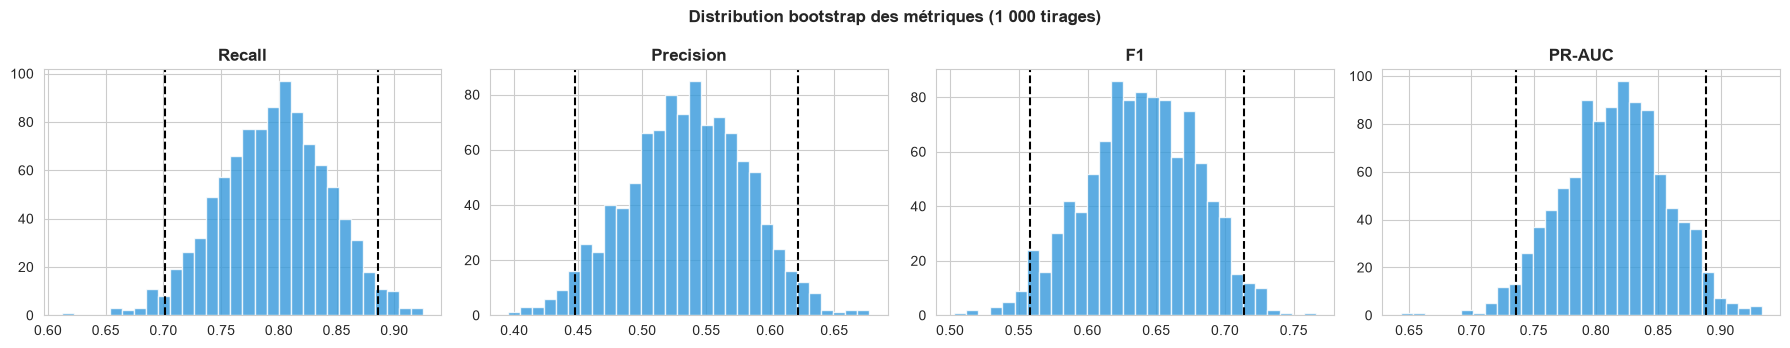

In [25]:
rng = np.random.default_rng(RANDOM_STATE)
yt, n = y_test.to_numpy(), len(y_test)
boot = []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    if yt[idx].sum() == 0:
        continue
    boot.append({
        "Recall": recall_score(yt[idx], y_pred[idx], zero_division=0),
        "Precision": precision_score(yt[idx], y_pred[idx], zero_division=0),
        "F1": f1_score(yt[idx], y_pred[idx], zero_division=0),
        "PR-AUC": average_precision_score(yt[idx], scores_test[idx]),
    })
boot = pd.DataFrame(boot)
IC = pd.DataFrame({
    "Valeur (test)": [recall_score(yt, y_pred), precision_score(yt, y_pred), f1_score(yt, y_pred),
                      average_precision_score(yt, scores_test)],
    "IC 95 % — bas": boot.quantile(0.025).values,
    "IC 95 % — haut": boot.quantile(0.975).values,
}, index=boot.columns)
display(IC.style.format("{:.3f}"))

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, col in zip(axes, boot.columns):
    ax.hist(boot[col], bins=30, color="#3498db", alpha=0.8)
    ax.axvline(IC.loc[col, "IC 95 % — bas"], color="k", ls="--")
    ax.axvline(IC.loc[col, "IC 95 % — haut"], color="k", ls="--")
    ax.set_title(col, fontweight="bold")
plt.suptitle("Distribution bootstrap des métriques (1 000 tirages)", fontweight="bold")
plt.tight_layout()
plt.show()

## 5.4 Stabilité dans le temps

### Performances par période

Le test couvre les dernières heures de la collecte. Nous le découpons en **4 périodes successives** pour voir si les performances restent stables.

In [26]:
periodes = []
for i, idx in enumerate(np.array_split(np.arange(len(X_test)), 4), start=1):
    t0, t1 = X_test["Time"].iloc[idx[0]] / 3600, X_test["Time"].iloc[idx[-1]] / 3600
    yt_p, yp_p = y_test.iloc[idx].to_numpy(), y_pred[idx]
    periodes.append({
        "Période": f"P{i} ({t0:.1f} h → {t1:.1f} h)",
        "Transactions": len(idx), "Fraudes": int(yt_p.sum()),
        "Détectées": int((yt_p & yp_p).sum()), "Fausses alertes": int(((yt_p == 0) & (yp_p == 1)).sum()),
        "Recall": recall_score(yt_p, yp_p, zero_division=0) if yt_p.sum() else np.nan,
        "Precision": precision_score(yt_p, yp_p, zero_division=0) if yp_p.sum() else np.nan,
    })
periodes = pd.DataFrame(periodes)
display(periodes.style.format({"Recall": "{:.3f}", "Precision": "{:.3f}"}))

,Période,Transactions,Fraudes,Détectées,Fausses alertes,Recall,Precision
0,P1 (40.3 h → 42.0 h),14187,22,20,12,0.909,0.625
1,P2 (42.0 h → 43.8 h),14187,30,23,8,0.767,0.742
2,P3 (43.8 h → 45.6 h),14186,11,10,16,0.909,0.385
3,P4 (45.6 h → 48.0 h),14186,11,6,16,0.545,0.273


### Découpage temporel ou aléatoire : quelle différence ?

Nous refaisons l'entraînement et l'évaluation avec un **découpage aléatoire stratifié** (même modèle, mêmes hyperparamètres, même seuil) pour mesurer à quel point un découpage aléatoire aurait **surestimé** les performances.

In [27]:
Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
pipe_aleatoire = clone(pipeline_final)
if "model__n_jobs" in pipe_aleatoire.get_params():
    pipe_aleatoire.set_params(model__n_jobs=-1)
pipe_aleatoire.fit(Xa_train, ya_train)
s_alea = scores_fraude(pipe_aleatoire, Xa_test)

comp_decoupage = pd.DataFrame({
    "Découpage temporel (retenu)": metriques(y_test, y_pred, scores_test),
    "Découpage aléatoire stratifié": metriques(ya_test, (s_alea >= SEUIL).astype(int), s_alea),
}).loc[["Recall", "Precision", "F1", "PR-AUC", "ROC-AUC", "TP", "FN", "FP"]]
display(comp_decoupage.style.format(precision=3))

,Découpage temporel (retenu),Découpage aléatoire stratifié
Recall,0.797,0.821
Precision,0.532,0.716
F1,0.638,0.765
PR-AUC,0.815,0.823
ROC-AUC,0.988,0.967
TP,59.000,78.000
FN,15.000,17.000
FP,52.000,31.000


### Lecture : le modèle est-il stable dans le temps ?

| Période | Fraudes | Détectées | Fausses alertes | Recall | Precision |
|---|---|---|---|---|---|
| P1 (40,3 h → 42,0 h) | 22 | 20 | 12 | 91 % | 63 % |
| P2 (42,0 h → 43,8 h) | 30 | 23 | 8 | 77 % | 74 % |
| P3 (43,8 h → 45,6 h) | 11 | 10 | 16 | 91 % | 39 % |
| P4 (45,6 h → 48,0 h) | 11 | 6 | 16 | **55 %** | **27 %** |

- **Les performances varient fortement d'une période à l'autre.** Avec 11 à 30 fraudes par période, une seule fraude change le recall de 3 à 9 points : une partie de ces écarts est du hasard.
- **La dernière période (P4) est nettement moins bonne** : 6 fraudes sur 11 détectées et 16 fausses alertes. Avec si peu de cas, on ne peut pas conclure à une dégradation durable. Mais c'est exactement le type de signal à surveiller en production (phase 7), et c'est pourquoi le modèle devrait être réentraîné régulièrement.

**Découpage temporel ou aléatoire ?**

| | Découpage temporel (retenu) | Découpage aléatoire |
|---|---|---|
| Recall | 79,7 % | 82,1 % |
| Precision | 53,2 % | 71,6 % |
| F1 | 0,638 | 0,765 |

Avec un découpage aléatoire, le modèle paraît meilleur, surtout en précision. Il s'entraîne alors sur des transactions **postérieures** à celles qu'il doit prédire, ce qui est impossible en réalité. **Le découpage aléatoire est trop optimiste** : le découpage temporel donne l'estimation réaliste de ce que le modèle ferait en production.

## 5.5 Expliquer le modèle

### Importance globale des variables

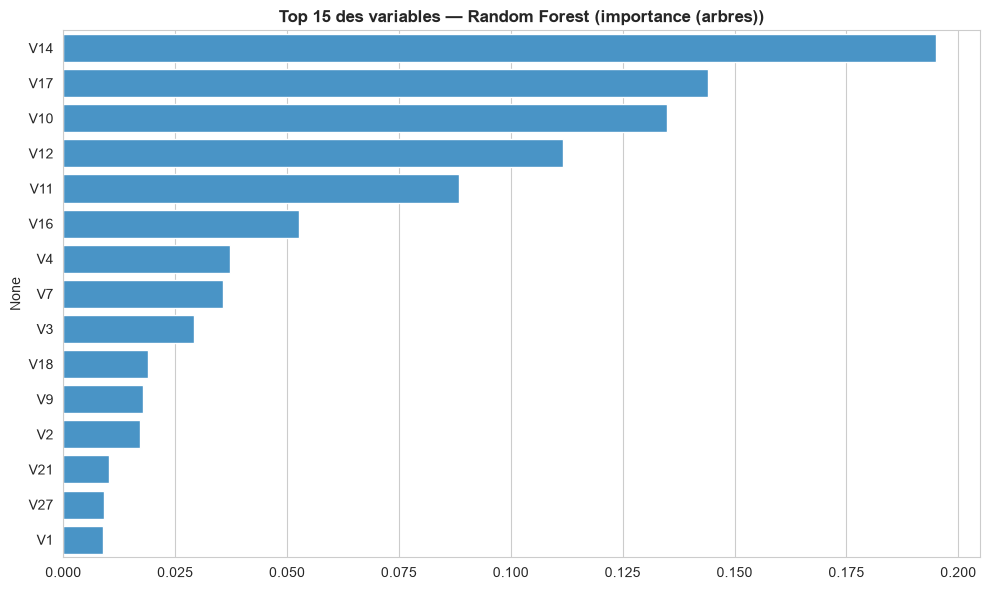

Top 5 : V14, V17, V10, V12, V11


In [28]:
modele_final = pipeline_final.named_steps["model"]


def transformer(pipeline, X):
    # Applique toutes les étapes de transformation du pipeline (sans le modèle ni le rééchantillonnage)
    Xt = X
    for nom, etape in pipeline.steps[:-1]:
        if hasattr(etape, "transform"):
            Xt = etape.transform(Xt)
    return pd.DataFrame(np.asarray(Xt), columns=COLONNES_MODELE, index=X.index)


if hasattr(modele_final, "feature_importances_"):
    importances, methode_imp = modele_final.feature_importances_, "importance (arbres)"
elif hasattr(modele_final, "coef_"):
    importances, methode_imp = np.abs(modele_final.coef_).ravel(), "|coefficient|"
else:
    from sklearn.inspection import permutation_importance
    ech = X_test.sample(n=min(20000, len(X_test)), random_state=RANDOM_STATE)
    importances = permutation_importance(pipeline_final, ech, y_test.loc[ech.index], scoring="average_precision",
                                         n_repeats=5, random_state=RANDOM_STATE, n_jobs=N_JOBS).importances_mean
    methode_imp = "importance par permutation"

imp = pd.Series(importances, index=COLONNES_MODELE).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(x=imp.head(15).values, y=imp.head(15).index, color="#3498db")
plt.title(f"Top 15 des variables — {MEILLEUR_NOM} ({methode_imp})", fontweight="bold")
plt.tight_layout()
plt.show()
print("Top 5 :", ", ".join(imp.head(5).index))

### Explication avec SHAP

L'importance globale dit **quelles** variables comptent, mais pas **dans quel sens** ni **pour quelle transaction**. Les **valeurs SHAP** (issues de la théorie des jeux) mesurent, pour chaque transaction, **la contribution de chaque variable** à son score de fraude :
- une valeur SHAP **positive** pousse vers « fraude » ;
- une valeur **négative** pousse vers « normale ».

C'est ce qui permet d'expliquer à un analyste (ou à un client) **pourquoi** une transaction a été signalée.

Valeurs SHAP calculées en 85 s pour 426 transactions


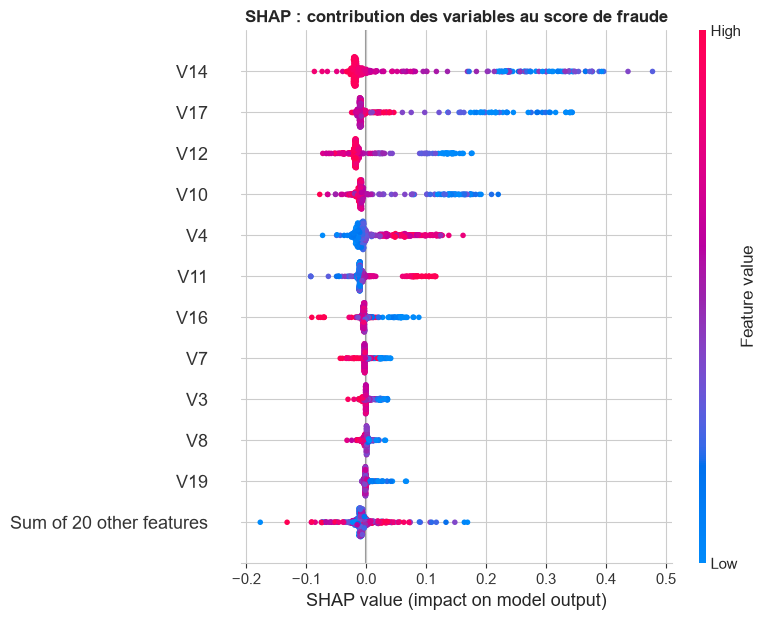

In [29]:
# Échantillon : toutes les fraudes et alertes du test + des transactions normales, pour garder un calcul rapide
idx_interessants = X_test.index[(y_test.to_numpy() == 1) | (y_pred == 1)]
idx_normaux = X_test.index[(y_test.to_numpy() == 0) & (y_pred == 0)].to_series().sample(
    n=min(300, len(X_test)), random_state=RANDOM_STATE).index
X_shap = transformer(pipeline_final, X_test.loc[idx_interessants.append(idx_normaux)])

debut = time.time()
try:
    explainer = shap.TreeExplainer(modele_final)
    valeurs = explainer(X_shap, check_additivity=False)
except Exception as e:
    print(f"TreeExplainer indisponible ({type(e).__name__}), utilisation de l'explainer générique")
    fond = shap.sample(X_shap, 100, random_state=RANDOM_STATE)
    explainer = shap.Explainer(lambda d: scores_fraude(modele_final, d), fond)
    valeurs = explainer(X_shap.iloc[:300])
if valeurs.values.ndim == 3:                      # certains modèles renvoient une valeur par classe
    valeurs = valeurs[:, :, 1]
print(f"Valeurs SHAP calculées en {time.time() - debut:.0f} s pour {valeurs.shape[0]} transactions")

plt.figure()
shap.plots.beeswarm(valeurs, max_display=12, show=False)
plt.title("SHAP : contribution des variables au score de fraude", fontweight="bold")
plt.tight_layout()
plt.show()

Transaction 240549 : montant 10.70, heure 18.0 h, score 1.000


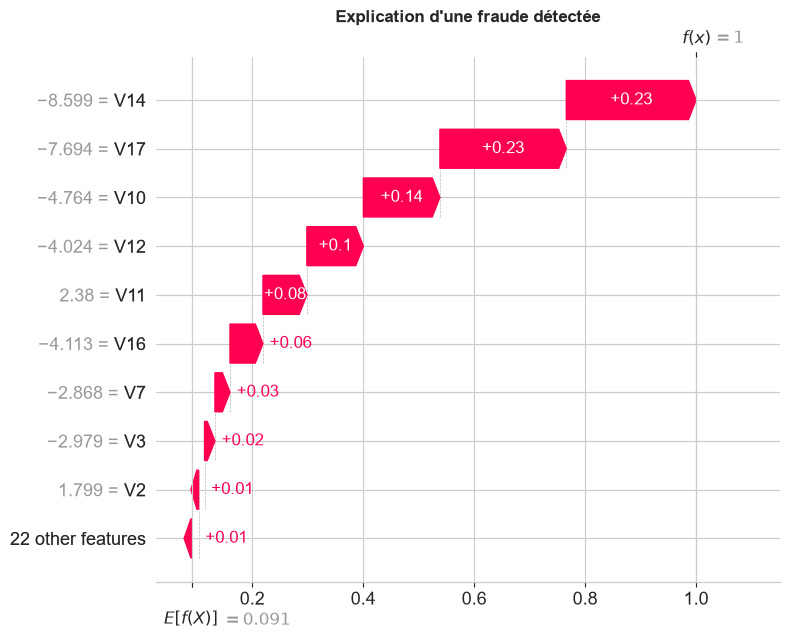

In [30]:
# Pourquoi cette transaction a-t-elle été signalée ? (la fraude détectée au score le plus élevé)
detectees = [i for i, ix in enumerate(X_shap.index) if y_test.loc[ix] == 1 and y_pred[X_test.index.get_loc(ix)] == 1]
i_ex = max(detectees, key=lambda i: scores_test[X_test.index.get_loc(X_shap.index[i])])
ix = X_shap.index[i_ex]
print(f"Transaction {ix} : montant {X_test.loc[ix, 'Amount']:.2f}, heure {heure_du_jour(X_test.loc[ix, 'Time']):.1f} h, "
      f"score {scores_test[X_test.index.get_loc(ix)]:.3f}")
plt.figure()
shap.plots.waterfall(valeurs[i_ex], max_display=10, show=False)
plt.title("Explication d'une fraude détectée", fontweight="bold")
plt.tight_layout()
plt.show()

### Interprétation

**Les variables clés** sont V14, V17, V12, V10, V4 et V11, les mêmes que celles repérées dans l'analyse exploratoire (phase 2). Le modèle a donc appris des signaux cohérents avec les données, et non des artefacts.

**Le sens des effets (graphique SHAP) :**
- pour **V14, V17, V12, V10 et V16**, des **valeurs basses** (points bleus) poussent fortement vers « fraude ». V14 très négatif est le signal le plus fort : jusqu'à +0,48 sur le score ;
- pour **V4 et V11**, c'est l'inverse : des **valeurs hautes** (points roses) augmentent le score de fraude ;
- le **montant** et l'**heure** n'apparaissent pas parmi les 11 variables les plus influentes : leur rôle est secondaire.

**Exemple d'une fraude détectée (graphique en cascade).** Pour une transaction moyenne, le score de départ est de 0,09. Pour cette fraude, V14 (−8,6) et V17 (−7,7) ajoutent chacun +0,23, puis V10 et V12 ajoutent +0,14 et +0,10. Le score atteint 1,0. C'est ce type d'explication qu'un analyste lirait pour comprendre **pourquoi** une transaction est signalée.

**Limite :** V1 à V28 sont anonymisées (ACP). Nous savons **quelles** variables comptent, mais pas **quel comportement** réel elles décrivent. En entreprise, l'équipe qui détient les données d'origine pourrait faire cette traduction.

## 5.6 Analyse des erreurs

Comprendre **où** le modèle se trompe indique **comment** l'améliorer :
- **fraudes ratées (FN)** : ont-elles quelque chose en commun (montant, heure, score) ?
- **fausses alertes (FP)** : quelles transactions normales ressemblent à des fraudes ?

,Nombre,Montant_médian,Montant_moyen,Part_nuit_pct,Score_médian,V14_médian,V17_médian,V10_médian,V12_médian
Groupe,,,,,,,,,
Fausse alerte (FP),52,2.89,582.642,23.077,0.352,-4.141,2.364,-0.565,-1.020
Fraude détectée (TP),59,2.00,90.337,10.169,0.960,-8.599,-3.688,-3.951,-4.837
Fraude ratée (FN),15,12.31,159.853,26.667,0.027,-2.106,1.095,0.329,-0.131
Normale acceptée (TN),56620,18.07,78.137,19.853,0.001,-0.103,-0.133,0.002,0.089


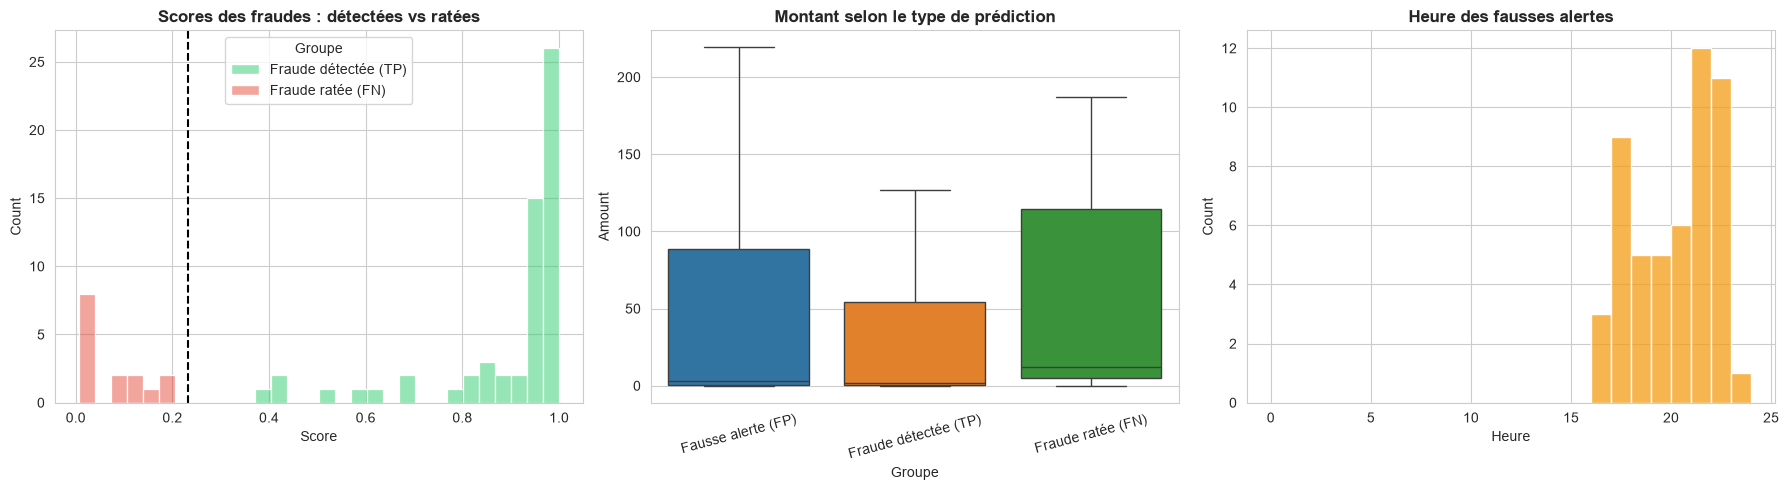

Les 10 fraudes ratées :


,Amount,Heure,Score,Groupe,V14,V17,V10,V12
248322,1096.99,18.864,0.024,Fraude ratée (FN),1.025,-0.007,-1.063,0.810
274961,634.30,22.342,0.116,Fraude ratée (FN),0.298,-0.898,1.458,-0.789
244645,357.95,18.445,0.118,Fraude ratée (FN),-2.683,1.746,-1.411,0.344
253404,187.11,19.524,0.009,Fraude ratée (FN),-2.106,0.880,-1.552,0.361
280611,42.53,23.319,0.006,Fraude ratée (FN),-2.254,1.095,-0.812,0.575
275040,19.95,22.356,0.011,Fraude ratée (FN),-2.116,1.430,0.350,-0.420
237582,17.39,17.577,0.185,Fraude ratée (FN),-3.395,0.827,0.502,-0.131
271500,12.31,21.870,0.167,Fraude ratée (FN),-1.669,3.334,-0.307,0.805
231118,8.00,16.833,0.173,Fraude ratée (FN),-4.199,2.760,-0.811,-0.429
253455,7.59,19.531,0.021,Fraude ratée (FN),0.082,-0.902,1.199,-1.025


In [31]:
analyse = X_test[["Amount"]].copy()
analyse["Heure"] = heure_du_jour(X_test["Time"])
analyse["Score"] = scores_test
analyse["Groupe"] = np.select(
    [(y_test == 1) & (y_pred == 1), (y_test == 1) & (y_pred == 0), (y_test == 0) & (y_pred == 1)],
    ["Fraude détectée (TP)", "Fraude ratée (FN)", "Fausse alerte (FP)"], default="Normale acceptée (TN)")
top_vars = imp.head(4).index.tolist()
analyse = analyse.join(transformer(pipeline_final, X_test)[top_vars])

synthese = analyse.groupby("Groupe").agg(
    Nombre=("Score", "size"), Montant_médian=("Amount", "median"), Montant_moyen=("Amount", "mean"),
    Part_nuit_pct=("Heure", lambda h: ((h < 7) | (h >= 22)).mean() * 100), Score_médian=("Score", "median"),
    **{f"{v}_médian": (v, "median") for v in top_vars})
display(synthese.round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fraudes = analyse[analyse["Groupe"].str.startswith("Fraude")]
sns.histplot(data=fraudes, x="Score", hue="Groupe", bins=30, ax=axes[0], palette=["#2ecc71", "#e74c3c"])
axes[0].axvline(SEUIL, color="k", ls="--", label="Seuil")
axes[0].set_title("Scores des fraudes : détectées vs ratées", fontweight="bold")

sns.boxplot(data=analyse[analyse["Groupe"] != "Normale acceptée (TN)"], x="Groupe", y="Amount", ax=axes[1],
            hue="Groupe", legend=False, showfliers=False)
axes[1].set_title("Montant selon le type de prédiction", fontweight="bold")
axes[1].tick_params(axis="x", rotation=15)

sns.histplot(data=analyse[analyse["Groupe"] == "Fausse alerte (FP)"], x="Heure", bins=24, binrange=(0, 24),
             ax=axes[2], color="#f39c12")
axes[2].set_title("Heure des fausses alertes", fontweight="bold")
plt.tight_layout()
plt.show()

print("Les 10 fraudes ratées :")
display(analyse[analyse["Groupe"] == "Fraude ratée (FN)"].sort_values("Amount", ascending=False).head(10).round(3))

### Interprétation

| Groupe | Nombre | Montant médian | V14 médian | V17 médian | Score médian |
|---|---|---|---|---|---|
| Fraude détectée (TP) | 59 | 2,00 € | −8,6 | −3,7 | 0,960 |
| **Fraude ratée (FN)** | 15 | 12,31 € | **−2,1** | **+1,1** | 0,027 |
| **Fausse alerte (FP)** | 52 | 2,89 € | **−4,1** | +2,4 | 0,352 |
| Normale acceptée (TN) | 56 620 | 18,07 € | −0,1 | −0,1 | 0,001 |

**Les fraudes ratées ressemblent à des transactions normales.** Leurs valeurs de V14, V17, V10 et V12 sont proches de celles des transactions normales, loin de celles des fraudes détectées. Leur score médian n'est que de 0,027 : aucun seuil raisonnable ne les attraperait. Avec les seules variables du dataset, ces fraudes sont **indétectables**. Il faudrait des variables de comportement (habitudes du client, nombre de transactions récentes sur la carte), absentes ici.

**Les fraudes ratées coûtent cher.** Deux d'entre elles (1 097 € et 634 €) représentent à elles seules **72 % du montant raté** (2 398 €). Le montant moyen d'une fraude ratée (160 €) dépasse celui d'une fraude détectée (90 €). Une piste d'amélioration serait de **pondérer l'apprentissage par le montant**.

**Les fausses alertes ressemblent à des fraudes.** Elles ont un V14 assez bas (−4,1), à mi-chemin entre normales et fraudes. Leur montant médian est faible (2,89 €), mais leur montant moyen est élevé (583 €) à cause de quelques gros achats. Ce sont des cas légitimement suspects : leur vérification par un analyste est justifiée.

---

# PHASE 6 — DEPLOYMENT (Déploiement)

## 6.1 Export du modèle

Nous sauvegardons dans `models/fraud_detection_model.joblib` tout ce qu'il faut pour utiliser le modèle :

- le **pipeline complet** (création de variables + mise à l'échelle + modèle) : il prend en entrée une transaction **brute**. Pour le recharger hors de ce notebook, il faut d'abord définir la fonction `ajouter_variables` (cellule de configuration) ;
- les **seuils** d'alerte et de blocage, et les hypothèses de coût qui ont servi à les choisir ;
- la **liste des colonnes** attendues ;
- les **performances** sur le test (avec leurs intervalles de confiance) et les **versions des bibliothèques** (un modèle doit être rechargé avec les mêmes versions).

In [32]:
CHEMIN_MODELE = MODELS_DIR / "fraud_detection_model.joblib"

import lightgbm, xgboost, imblearn
paquet = {
    "pipeline": pipeline_final,
    "seuil_alerte": SEUIL,
    "seuil_blocage": SEUIL_BLOCAGE,
    "colonnes_entree": COLONNES_BRUTES,
    "colonnes_modele": COLONNES_MODELE,
    "nom_modele": MEILLEUR_NOM,
    "strategie_desequilibre": STRATEGIE,
    "hyperparametres": PARAMS_RETENUS,
    "hypotheses": {"cout_verification_eur": COUT_VERIFICATION, "capacite_alertes_jour": CAPACITE_ALERTES_JOUR,
                   "precision_blocage": PRECISION_BLOCAGE},
    "metriques_test": {k: float(v) for k, v in res_test.iloc[:, 0].items()},
    "intervalles_confiance_95": {k: [float(r["IC 95 % — bas"]), float(r["IC 95 % — haut"])] for k, r in IC.iterrows()},
    "periode_entrainement_heures": [0.0, float(X_train["Time"].max() / 3600)],
    "versions": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__, "pandas": pd.__version__,
                 "numpy": np.__version__, "lightgbm": lightgbm.__version__, "xgboost": xgboost.__version__,
                 "imbalanced-learn": imblearn.__version__},
    "date": datetime.now().isoformat(timespec="seconds"),
}
joblib.dump(paquet, CHEMIN_MODELE, compress=3)
with open(MODELS_DIR / "fraud_detection_model_infos.json", "w", encoding="utf-8") as f:
    json.dump({k: v for k, v in paquet.items() if k != "pipeline"}, f, indent=2, ensure_ascii=False, default=str)

print(f"✓ Modèle exporté : {CHEMIN_MODELE} ({CHEMIN_MODELE.stat().st_size / 1024**2:.1f} Mo)")
print(f"✓ Fiche descriptive : {MODELS_DIR / 'fraud_detection_model_infos.json'}")

✓ Modèle exporté : C:\Users\DIGITAL MARKET\Desktop\Financial_Fraud_Intelligence\models\fraud_detection_model.joblib (10.1 Mo)
✓ Fiche descriptive : C:\Users\DIGITAL MARKET\Desktop\Financial_Fraud_Intelligence\models\fraud_detection_model_infos.json


## 6.2 Fonction de prédiction réutilisable

La fonction `predire_fraude` recharge le modèle exporté et renvoie, pour chaque transaction, son **score** et la **décision en 3 niveaux**. Nous la testons sur de vraies transactions du test et mesurons le **temps de réponse**.

In [33]:
def predire_fraude(transactions, chemin_modele=CHEMIN_MODELE):
    # Prédit la fraude pour un DataFrame de transactions brutes (Time, V1..V28, Amount)
    p = joblib.load(chemin_modele)
    score = scores_fraude(p["pipeline"], transactions[p["colonnes_entree"]])
    niveau = np.where(score >= p["seuil_blocage"], "🔴 Bloquer",
                      np.where(score >= p["seuil_alerte"], "🟠 Vérifier", "🟢 Accepter"))
    return pd.DataFrame({"score_fraude": np.round(score, 4), "décision": niveau}, index=transactions.index)


demo = pd.concat([X_test[y_test == 1].sample(5, random_state=1), X_test[y_test == 0].sample(5, random_state=1)])
resultat = predire_fraude(demo)
resultat.insert(0, "réalité", np.where(y_test.loc[demo.index] == 1, "Fraude", "Normale"))
display(resultat)

pipe_charge = joblib.load(CHEMIN_MODELE)["pipeline"]
une = X_test.iloc[[0]]
debut = time.perf_counter()
for _ in range(50):
    scores_fraude(pipe_charge, une)
LATENCE_MS = (time.perf_counter() - debut) / 50 * 1000
print(f"Temps moyen de prédiction : {LATENCE_MS:.1f} ms par transaction")

,réalité,score_fraude,décision
239334,Fraude,0.4140,🟠 Vérifier
260962,Fraude,0.9596,🔴 Bloquer
234760,Fraude,0.9863,🔴 Bloquer
279090,Fraude,0.9002,🔴 Bloquer
260512,Fraude,0.8401,🔴 Bloquer
227496,Normale,0.0000,🟢 Accepter
260591,Normale,0.0000,🟢 Accepter
258603,Normale,0.0000,🟢 Accepter
271835,Normale,0.0059,🟢 Accepter
258342,Normale,0.0166,🟢 Accepter


Temps moyen de prédiction : 37.1 ms par transaction


## 6.3 Mise en production envisagée

Dans une vraie banque, le déploiement irait plus loin.

**Intégration temps réel.** Le modèle exporté serait servi par une **API** (par exemple avec Django ou FastAPI), appelée par le système d'autorisation de paiement pendant la transaction. Il faut une réponse en quelques millisecondes : modèle chargé une seule fois en mémoire, plusieurs instances derrière un répartiteur de charge.

**Combinaison avec des règles métier.** Le score s'ajoute aux règles existantes (listes noires, plafonds, pays interdits) et se traduit en 3 niveaux : 🟢 accepter, 🟠 vérifier, 🔴 bloquer.

**Vérification humaine et boucle de retour.** Les analystes traitent les alertes 🟠. Leur verdict (« fraude confirmée » ou « fausse alerte ») est enregistré et devient une **nouvelle étiquette** pour réentraîner le modèle.

## Phase 7 — Suivi dans le temps (envisagé)

| Action | Comment | Fréquence |
|---|---|---|
| **Surveiller les données** (*drift*) | comparer la distribution des variables et des scores à celle de l'entraînement (indice PSI) | quotidienne |
| **Surveiller le volume d'alertes** | rester sous la capacité de l'équipe ; une hausse brutale signale un problème | en continu |
| **Mesurer precision et recall** | dès que les vraies étiquettes arrivent (*chargebacks*, souvent **plusieurs semaines** plus tard) | mensuelle |
| **Réentraîner** | les fraudeurs changent de méthode : réentraîner sur les données récentes, valider sur la période suivante | mensuelle ou si dérive |
| **Documenter** | données, choix, seuils, hypothèses de coût, limites, version du modèle (voir `fraud_detection_model_infos.json`) | à chaque version |

---

# CONCLUSION GÉNÉRALE

## Résumé du projet

Ce projet a suivi la méthode **CRISP-DM** pour construire un système de détection de fraude bancaire dont la priorité est de **détecter le maximum de fraudes**, sous une contrainte de capacité de vérification.

**Phase 1 — Cadrage :** une fraude ratée coûte son montant, une alerte coûte 5 €, l'équipe peut traiter 500 alertes par jour. Les modèles sont comparés au **recall à précision ≥ 50 %**, et le seuil est choisi en **minimisant le coût** sous cette capacité.

**Phase 2 — Données :** 284 807 transactions sur 48 heures, 492 fraudes (0,17 %), aucune valeur manquante, 1 081 doublons. V14, V17, V12 et V10 distinguent nettement les fraudes, qui sont aussi plus fréquentes la nuit.

**Phase 3 — Préparation :** suppression des doublons, **découpage temporel** (les 80 % les plus anciennes pour apprendre, les 20 % les plus récentes pour tester), ajout du montant en log et de l'heure cyclique. Le tout est intégré dans un **Pipeline** pour éviter toute fuite d'information.

**Phase 4 — Modélisation :**
- 2 points de comparaison : une règle simple (V14) et un modèle non supervisé ;
- 15 algorithmes comparés en validation croisée à 5 plis ;
- **Random Forest** retenu (recall 0,867 à précision ≥ 50 %), à égalité pratique avec Extra Trees et XGBoost ;
- 4 stratégies de déséquilibre testées, **SMOTE** retenu ;
- optimisation des hyperparamètres : gain très faible (+0,003, une fraude) pour près d'une heure de calcul ;
- seuil d'alerte **0,233**, seuil de blocage **0,614**.

**Phase 5 — Évaluation** sur les 7,7 dernières heures (74 fraudes jamais vues) :
- **Recall : 79,7 %** (59 fraudes détectées sur 74), intervalle de confiance à 95 % de 70 % à 89 % ;
- **Precision : 53,2 %**, avec 52 fausses alertes sur 56 672 transactions normales (0,09 %) ;
- **PR-AUC : 0,815**, et **348 alertes par jour** ;
- **coût total : 2 953 €** contre 7 728 € sans modèle, soit 62 % d'économie, mieux que la Logistic Regression (3 014 €) et la règle simple (4 626 €).

**Phase 6 — Déploiement :** le pipeline complet (création des variables, mise à l'échelle, modèle) est exporté avec ses deux seuils dans `models/fraud_detection_model.joblib`, avec une fiche JSON. La fonction `predire_fraude()` renvoie une décision en 3 niveaux : accepter, vérifier ou bloquer.

## Ce qu'il faut retenir

1. **L'accuracy est trompeuse** : répondre toujours « normal » donne 99,83 % sans détecter une seule fraude.
2. **Il faut comparer les modèles à précision égale** : un recall élevé obtenu avec des milliers de fausses alertes est inutilisable.
3. **Le seuil est une décision métier** : il dépend du coût d'une vérification et de la capacité de l'équipe, et il change avec eux.
4. **Le découpage aléatoire surestime les performances** (précision 72 % contre 53 % en temporel) : il faut évaluer le modèle sur le futur.
5. **Les forêts d'arbres et le boosting moderne** (Random Forest, Extra Trees, XGBoost) sont les plus performants sur ce problème.

## Limites

- **Peu de fraudes** : le test n'en contient que 74, donc chaque fraude pèse 1,4 point de recall. L'intervalle de confiance du recall est large (70 % à 89 %).
- **Objectifs non atteints** : le recall (79,7 %) est juste sous l'objectif de 80 %, et le temps de prédiction (37 ms) dépasse largement l'objectif de 10 ms.
- **Instabilité dans le temps** : sur la dernière période, seules 6 fraudes sur 11 sont détectées.
- **Seulement deux jours de données, en 2013** : les techniques de fraude ont évolué depuis.
- **Variables anonymisées et sans identifiant de client ou de carte** : impossible d'interpréter les variables ou de calculer des variables de comportement.
- **Coûts hypothétiques** : le seuil devra être recalculé avec les vrais coûts de la banque.

## Perspectives d'amélioration

- **Réduire le temps de prédiction** : utiliser XGBoost (aussi performant ici et beaucoup plus rapide), réduire le nombre d'arbres ou traiter les transactions par lots.
- **Ajouter des variables de comportement** (habitudes du client, fréquence d'utilisation de la carte) : c'est la seule façon d'attraper les fraudes qui ressemblent à des transactions normales.
- **Pondérer l'apprentissage par le montant**, car les fraudes ratées sont plutôt de gros montants.
- **Réentraîner régulièrement** le modèle et **surveiller** le volume d'alertes et la distribution des scores (phase 7).
- **Calibrer les probabilités** pour que le score soit directement interprétable comme une probabilité de fraude.

---

**Fin du notebook**